# **Telecom Network Intelligence & AIOps Simulation**

A synthetic telecom network environment informed by publicly available telecom information and industry practices. The project simulates network topology, traffic, performance, events, and faults for network analytics, anomaly detection, forecasting, fault prediction, and root cause analysis.

## **Executive Summary**

### **Project objective**

Generate realistic synthetic raw network data that reflects plausible telecom network behaviour, since real operator network data is not publicly available.

The data will be used to derive network KPIs, identify performance issues, and build analytics and AI/ML solutions for proactive network monitoring and decision making.

### **Business / operational problems**

Network operators need to know:

- How is the network performing?
- Where are problems occurring?
- Is performance likely to deteriorate?
- What is causing the problem?
- Where is additional capacity or intervention needed?

This project develops an analytics and AI/ML layer that turns network observations into actionable network intelligence.

### **Use cases**

1. Network Performance Analytics: Understand overall network behaviour and identify performance trends across regions, sites, cells, and network layers.
2. Predictive Fault Detection: Identify network conditions that may indicate an emerging equipment or infrastructure failure.
3. Congestion Prediction: Predict cells or network components that are likely to experience capacity or performance degradation.
4. Traffic Forecasting: Forecast future network traffic to support capacity planning and resource allocation.
5. Anomaly Detection: Detect unusual network behaviour that deviates from expected operating patterns.
6. Root Cause Analysis: Use network performance, events, temporal relationships, and topology to identify and rank likely causes of observed degradation.

### **Scope, Methodology and Assumptions**

* **Network structure:** A simplified five region network covering Lagos, West, East, South/Port Harcourt, and North, with 50 sites, approximately 150 cells, 10 aggregation nodes, 20 transport links, and 3 core nodes.

* **Network configuration:** Each site contains 2–6 cells, with approximately 3 cells per site on average. The network uses 4G and 5G, with 5G concentrated more heavily in higher demand and urban areas.

* **Topology:** Aggregation and transport infrastructure is shared, allowing multiple sites and cells to depend on common network components and creating meaningful dependencies for congestion analysis and root cause analysis.

* **Temporal behaviour:** The simulation covers 90 days at a 15 minute telemetry interval, with traffic and performance varying by time of day, day of week, region, site, and technology.

* **Network behaviour:** Raw observations reflect relationships between demand, traffic, capacity, utilization, performance, and network events rather than independently generated KPIs.

* **Raw Data Transformation:** The simulation generates underlying network observations representative of data collected from network equipment and network operations and monitoring systems. These observations form the basis for deriving network KPIs, anomalies, fault labels, root cause hypotheses, and model predictions rather than generating these outputs directly.

* **Assumptions:** The network design combines telecom domain knowledge, publicly available information, and explicit simulation assumptions. Synthetic values represent plausible network behaviour and are not presented as actual operator network data.

## Install and Import Necessary Libraries

In [ ]:
!pip install k-means-constrained -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 8.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 29.8/29.8 MB 7.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.4/137.4 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 323.4/323.4 kB 6.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-ai-generativelanguage 0.6.15 requires protobuf!=4.21.0,!=4.21.1,!=4.21.2,!=4.21.3,!=4.21.4,!=4.21.5,<6.0.0dev,>=3.20.2, but you have protobuf 6.33.6 which is incompatible.
grpcio-status 1.71.2 requires protobuf<6.0dev,>=5.26.1, but you have protobuf 6.33.6 which is incompatible.


In [ ]:
import networkx as nx
import numpy as np
import pandas as pd

from dataclasses import dataclass
from k_means_constrained import KMeansConstrained
from scipy.spatial import cKDTree
from scipy.spatial.distance import pdist, squareform


In [ ]:
pd.set_option("display.max_columns", None)

## Generate Raw Telecom Network Dataset

### Static Toplogy Dataset

#### Configurations

In [ ]:
NETWORK_CONFIG = {
    "n_regions": 5,             # geographical/organizational grouping.
    "n_sites": 50,              # physical location where telecommunications equipment is deployed.
    "n_aggregation_nodes": 10,  # aggregation node/router collects traffic and sends to the transport network
    "n_transport_links": 20,    # Carries aggregate traffic from cell sites or local aggregation nodes back to the main core network (Backhaul)
    "n_core_nodes": 5,          # central engine for functions such as subscriber/session management and connectivity toward services.
    "seed": 42,
}

rng = np.random.default_rng(NETWORK_CONFIG["seed"])  # for reproducibility

REGION_INFO = {
    "Lagos": {"primary_hub": "Lagos",         "population_pressure": "very_high",   "urbanization": "very_high",   "traffic_demand": "very_high"},
    "West":  {"primary_hub": "Ibadan",        "population_pressure": "high",        "urbanization": "high",        "traffic_demand": "high"},
    "North": {"primary_hub": "Abuja/Kaduna",  "population_pressure": "high",        "urbanization": "medium_high", "traffic_demand": "high"},
    "South": {"primary_hub": "Port Harcourt", "population_pressure": "medium_high", "urbanization": "high",        "traffic_demand": "high"},
    "East":  {"primary_hub": "Enugu",         "population_pressure": "medium",      "urbanization": "medium_high", "traffic_demand": "medium_high"},
}

# REGION_ANCHORS = {
#     "Lagos": (6.5244, 3.3792), "West": (7.3775, 3.9470), "North": (9.0765, 7.3986),
#     "South": (4.8156, 7.0498), "East": (6.4413, 7.4988),
# }

# REGION_SPREAD_DEG = {"Lagos": 0.12, "West": 0.25, "North": 0.45, "South": 0.20, "East": 0.30}

REGION_ANCHORS = {
    "Lagos": (6.5244, 3.3792),
    "West":  (7.3775, 3.9470),
    "North": (10.5, 8.5),      # was (9.0765, 7.3986) — shift toward Kano/Kaduna corridor center
    "South": (4.8156, 7.0498),
    "East":  (6.4413, 7.4988),
}

REGION_SPREAD_DEG = {
    "Lagos": 0.12, "West": 0.25,
    "North": 1.8,   # was 0.45 — North needs to span a genuinely large footprint
    "South": 0.20, "East": 0.30,
}

# Deliberately NOT aligned to REGION_ANCHORS — a core sitting exactly on a region hub
# would make "nearest core" collapse to "your own region's core" almost every time.
CORE_ANCHORS = [
    (7.00, 4.50),   # Lagos–West corridor: highest combined traffic, off-center from either hub
    (9.50, 8.20),   # North, offset from Abuja/Kaduna
    (5.60, 6.20),   # South/East corridor
    (6.90, 6.00),   # Central pooling point, roughly equidistant from all regions
    (8.20, 5.30),   # Secondary North/West pooling point
]

# cell capacity, driven only by technology + band
CELL_CAPACITY_MBPS = {
    ("4G", "700MHz"): 75, ("4G", "1800MHz"): 100, ("4G", "2100MHz"): 110, ("4G", "2600MHz"): 150,
    ("5G", "2100MHz"): 300, ("5G", "2600MHz"): 500, ("5G", "3500MHz"): 800,
}

# REGION DEMAND MULTIPLIER
REGION_FACTOR_VALUES = {"very_low": 0.70, "low": 0.80, "low_medium": 0.90, "medium": 1.00,
                         "medium_high": 1.10, "high": 1.20, "very_high": 1.35}

SITE_TYPE_MULTIPLIER = {"urban": 1.15, "suburban": 1.00, "rural": 0.70}

TECH_MULTIPLIER = {"4G": 1.00, "5G": 1.15}

CELL_TARGET_UTILIZATION_BY_SITE_TYPE = {"urban": 0.65, "suburban": 0.50, "rural": 0.35}


In [ ]:
# Helper Functions

def factor_lookup(factor):
    scale = {"very_high": 10, "high": 7.5, "medium_high": 6, "medium": 5,
             "low_medium": 4, "low": 3, "very_low": 1}
    if factor not in scale:
        raise ValueError(f"Unrecognized factor level: {factor!r}")
    return scale[factor]

In [ ]:
## Create Region table

def create_regions(region_info, n_sites, anchors=REGION_ANCHORS):
    weighted = {}
    for region, info in region_info.items():
        weight = (factor_lookup(info["population_pressure"]) * 0.50
                  + factor_lookup(info["urbanization"]) * 0.15
                  + factor_lookup(info["traffic_demand"]) * 0.35)
        weighted[region] = {**info, "site_allocation_weight": weight}

    total_weight = sum(v["site_allocation_weight"] for v in weighted.values())

    rows = []
    for i, (region, info) in enumerate(weighted.items(), start=1):
        lat, lon = anchors[region]
        rows.append({
            "region_id": f"region_{i:03d}",
            "region_name": region,
            "hub_city": info["primary_hub"],
            "population_factor": info["population_pressure"],
            "urbanization_factor": info["urbanization"],
            "traffic_demand_factor": info["traffic_demand"],
            "latitude": lat,
            "longitude": lon,
            "site_target": round(info["site_allocation_weight"] / total_weight * n_sites),
        })
    return pd.DataFrame(rows)

def add_region_demand_multiplier(regions):
    regions = regions.copy()
    for col in ["population_factor", "urbanization_factor", "traffic_demand_factor"]:
        regions[f"{col}_score"] = regions[col].map(REGION_FACTOR_VALUES)
        if regions[f"{col}_score"].isna().any():
            raise ValueError(f"Unmapped value in {col}")
    regions["region_demand_multiplier"] = (
        0.50 * regions["population_factor_score"]
        + 0.15 * regions["urbanization_factor_score"]
        + 0.35 * regions["traffic_demand_factor_score"]
    )
    regions["region_demand_multiplier"] /= regions["region_demand_multiplier"].mean()  # relative, not absolute
    return regions

In [ ]:
## # Create Site information

def create_sites(regions):
    rows = []
    cnt = 1
    for row in regions.itertuples():
        for _ in range(row.site_target):
            rows.append({"region_id": row.region_id, "site_id": f"site_{cnt:03d}"})
            cnt += 1
    return pd.DataFrame(rows)

# assign coordinates to site
def assign_site_coordinates(sites, regions, spread_lookup=REGION_SPREAD_DEG, rng=rng):
    region_lookup = regions.set_index("region_id")[["region_name", "latitude", "longitude"]]
    sites = sites.copy()
    lats, lons = [], []
    for region_id in sites["region_id"]:
        name, base_lat, base_lon = region_lookup.loc[region_id]
        spread = spread_lookup[name]
        lats.append(np.clip(base_lat + rng.normal(0, spread), base_lat - 3*spread, base_lat + 3*spread))
        lons.append(np.clip(base_lon + rng.normal(0, spread), base_lon - 3*spread, base_lon + 3*spread))
    sites["latitude"], sites["longitude"] = lats, lons
    return sites

# assign types (urban, suburban and rural) to sites
def assign_site_type(sites, regions):
    region_lookup = regions.set_index("region_id")[["urbanization_factor", "latitude", "longitude"]]
    sites = sites.copy()

    def classify(row):
        urban_factor, hub_lat, hub_lon = region_lookup.loc[row.region_id]
        dist_from_hub = np.hypot(row.latitude - hub_lat, row.longitude - hub_lon)
        if dist_from_hub < 0.15 and urban_factor in ("very_high", "high"):
            return "urban"
        elif dist_from_hub < 0.35:
            return "suburban"
        return "rural"

    sites["site_type"] = sites.apply(classify, axis=1)
    return sites

In [ ]:
# Create cells

def create_cells(regions, sites, rng=rng):
    cell_probs = {
        "Lagos": ([1,2,3,4,5,6], [0.00,0.10,0.45,0.20,0.15,0.10], [0.40,0.60]),
        "West":  ([1,2,3,4,5,6], [0.05,0.15,0.50,0.15,0.10,0.05], [0.50,0.50]),
        "North": ([1,2,3,4,5,6], [0.10,0.15,0.50,0.15,0.08,0.02], [0.60,0.40]),
    }
    default = ([1,2,3,4,5,6], [0.10,0.20,0.60,0.08,0.02,0.00], [0.75,0.25])

    rows = []
    cnt = 1
    for region in regions.itertuples(index=False):
        region_sites = sites[sites.region_id == region.region_id]
        n = len(region_sites)  # <- actual count, not region.site_target
        counts, count_probs, tech_probs = cell_probs.get(region.region_name, default)

        cell_distr = rng.choice(counts, n, p=count_probs)
        tech_distr = rng.choice(["4G", "5G"], n, p=tech_probs)

        for site_row, n_cells, tech in zip(region_sites.itertuples(index=False), cell_distr, tech_distr):
            for _ in range(n_cells):
                rows.append({"site_id": site_row.site_id, "cell_id": f"cell_{cnt:03d}",
                             "region_id": region.region_id, "technology": tech})
                cnt += 1
    return pd.DataFrame(rows)

def assign_sector_and_band(cells, rng=rng):
    cells = cells.copy()
    cells["sector"] = cells.groupby("site_id").cumcount() % 3 + 1

    band_map = {
        "4G": (["700MHz","1800MHz","2100MHz","2600MHz"], [0.15,0.35,0.30,0.20]),
        "5G": (["2100MHz","2600MHz","3500MHz"], [0.15,0.25,0.60]),
    }
    cells["band"] = cells["technology"].apply(
        lambda t: rng.choice(band_map[t][0], p=band_map[t][1])
    )
    return cells

def assign_cell_capacity(cells, capacity_map=CELL_CAPACITY_MBPS):
    cells = cells.copy()
    keys = list(zip(cells["technology"], cells["band"]))
    cells["cell_capacity_mbps"] = pd.Series(keys, index=cells.index).map(capacity_map)
    missing = cells[cells["cell_capacity_mbps"].isna()]
    if not missing.empty:
        raise ValueError(f"No capacity mapping for:\n{missing[['technology','band']].drop_duplicates()}")
    return cells

def assign_baseline_heterogeneity(cells, rng, watch_fraction=0.12, watch_range=(0.75, 0.85)):
    """Gives each cell a persistent 'identity' instead of every cell in the same
    (technology, site_type) bucket behaving identically up to per-timestep noise.
    - quality_offset_db: a fixed radio-quality offset per cell, applied on top of the
      existing bucket baseline in generate_ran_telemetry.
    - demand_variation_factor: a fixed demand multiplier per cell, so cells in the
      same bucket don't all run at exactly the same average utilization.
    - watch_utilization_override: for a deliberately chosen subset of cells, pins
      their target utilization into a persistent 70-85% band with NO fault entry —
      this is what creates a Healthy -> Watch -> Degraded -> Fault continuum instead
      of only Healthy/Fault.
    """
    cells = cells.copy()
    n = len(cells)
    cells["quality_offset_db"] = rng.normal(0, 1.5, n)
    cells["demand_variation_factor"] = rng.uniform(0.85, 1.20, n)

    watch_mask = rng.random(n) < watch_fraction
    cells["watch_utilization_override"] = np.where(watch_mask, rng.uniform(*watch_range, n), np.nan)
    return cells


#    compute_site_demand now derives demand FROM cell capacity,
#    instead of an independent hardcoded Gbps table. Same output schema
#    (site_id, site_demand) so nothing downstream needs to change.

def compute_site_demand(sites, cells, target_util=CELL_TARGET_UTILIZATION_BY_SITE_TYPE):
    """Busy-hour offered load per site, in Gbps. Demand = cell_capacity * target
    utilization for that site's environment — so demand can never be an arbitrary
    number disconnected from what the cell can actually carry."""
    merged = cells.merge(sites[["site_id", "site_type"]], on="site_id")
    merged["target_utilization"] = merged["site_type"].map(target_util)
    merged["cell_demand_gbps"] = merged["cell_capacity_mbps"] * merged["target_utilization"] / 1000
    return merged.groupby("site_id")["cell_demand_gbps"].sum().rename("site_demand").reset_index()

In [ ]:
def assign_aggregation_nodes(sites, n_clusters=10, size_min=3, size_max=7, seed=NETWORK_CONFIG["seed"]):
    sites = sites.copy()
    X = sites[["latitude", "longitude"]].to_numpy()
    clf = KMeansConstrained(n_clusters=n_clusters, size_min=size_min, size_max=size_max, random_state=seed)
    sites["aggregation_id"] = [f"agg_{i+1:03d}" for i in clf.fit_predict(X)]
    return sites, clf.cluster_centers_

def create_aggregation_nodes(cluster_centers):
    return pd.DataFrame([
        {"aggregation_id": f"agg_{i+1:03d}", "latitude": lat, "longitude": lon}
        for i, (lat, lon) in enumerate(cluster_centers)
    ])

# def compute_design_load(regions, sites, cells, base_utilization=0.50):
#     regions = add_region_demand_multiplier(regions)
#     df = (cells.merge(sites[["site_id", "site_type", "aggregation_id"]], on="site_id")
#                 .merge(regions[["region_id", "region_demand_multiplier"]], on="region_id"))

#     df["target_utilization"] = (
#         base_utilization * df["region_demand_multiplier"]
#         * df["site_type"].map(SITE_TYPE_MULTIPLIER)
#         * df["technology"].map(TECH_MULTIPLIER)
#     ).clip(0.20, 0.85)  # keep design-time load below full capacity; operational sim can exceed this later

#     df["cell_demand_gbps"] = df["cell_capacity_mbps"] * df["target_utilization"] / 1000

#     site_load = (df.groupby(["site_id", "aggregation_id"], as_index=False)["cell_demand_gbps"]
#                    .sum().rename(columns={"cell_demand_gbps": "site_demand_gbps"}))
#     agg_load = (site_load.groupby("aggregation_id", as_index=False)["site_demand_gbps"]
#                           .sum().rename(columns={"site_demand_gbps": "aggregation_demand_gbps"}))
#     return {"cell_load": df, "site_load": site_load, "aggregation_load": agg_load}

def compute_design_load(regions, sites, cells, base_utilization=0.50):
    regions = add_region_demand_multiplier(regions)
    df = (cells.merge(sites[["site_id", "site_type", "aggregation_id"]], on="site_id") #, "region_id"
                .merge(regions[["region_id", "region_demand_multiplier"]], on="region_id"))

    df["target_utilization"] = (
        base_utilization * df["region_demand_multiplier"]
        * df["site_type"].map(SITE_TYPE_MULTIPLIER)
        * df["technology"].map(TECH_MULTIPLIER)
        * df["demand_variation_factor"]                       # NEW — persistent per-cell demand variation
    ).clip(0.20, 0.85)

    # NEW — Watch-band cells override the formula entirely with a pinned high-utilization band
    df["target_utilization"] = df["watch_utilization_override"].combine_first(df["target_utilization"])

    df["cell_demand_gbps"] = df["cell_capacity_mbps"] * df["target_utilization"] / 1000

    site_load = (df.groupby(["site_id", "aggregation_id"], as_index=False)["cell_demand_gbps"]
                   .sum().rename(columns={"cell_demand_gbps": "site_demand_gbps"}))
    agg_load = (site_load.groupby("aggregation_id", as_index=False)["site_demand_gbps"]
                          .sum().rename(columns={"site_demand_gbps": "aggregation_demand_gbps"}))
    return {"cell_load": df, "site_load": site_load, "aggregation_load": agg_load}

def assign_aggregation_capacity(regions, sites, cells, aggregations, headroom_factor=1.4):
    agg_demand = compute_design_load(regions, sites, cells)["aggregation_load"].set_index("aggregation_id")["aggregation_demand_gbps"]
    aggregations = aggregations.drop(columns="capacity", errors="ignore").copy()
    aggregations["capacity"] = (aggregations["aggregation_id"].map(agg_demand) * headroom_factor).round(1)
    return aggregations


In [ ]:
# Transport Link

# Distance + backhaul links
def haversine_km(lat1, lon1, lat2, lon2):
    """Vectorized haversine distance in km. Works on scalars, arrays, or Series of matching shape."""
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1)/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin((lon2 - lon1)/2)**2
    return 2 * 6371 * np.arcsin(np.sqrt(a))

# Site to aggregation node link
def build_backhaul_links(regions, sites, cells, aggregations, headroom_factor=1.5, min_capacity_gbps=0.3):
    """headroom_factor raised 1.2 -> 1.5: backhaul carries one site's raw, unsmoothed
    demand with no multiplexing gain (unlike aggregation, which pools ~5 sites and
    benefits from bursts partially cancelling out) — so it needs MORE relative margin,
    not less. min_capacity_gbps floors very small single-cell rural sites at a realistic
    minimum link size, rather than letting a tiny demand value round to something that
    creates artificial >100% utilization.
    """
    site_load = compute_design_load(regions, sites, cells)["site_load"]
    merged = (sites.merge(aggregations, on="aggregation_id", suffixes=("_site", "_agg"))
                    .merge(site_load[["site_id", "site_demand_gbps"]], on="site_id"))
    merged["distance_km"] = haversine_km(merged.latitude_site, merged.longitude_site,
                                          merged.latitude_agg, merged.longitude_agg).round(2)

    # full precision for the math; only floor + a wider rounding step for storage
    raw_capacity = merged["site_demand_gbps"] * headroom_factor
    merged["capacity"] = np.maximum(raw_capacity, min_capacity_gbps).round(3)  # 3dp, not 1dp

    out = merged.rename(columns={"site_id": "source_id", "aggregation_id": "target_id"})
    out["source_type"], out["target_type"], out["link_type"] = "site", "aggregation", "backhaul"
    return out[["source_id", "source_type", "target_id", "target_type", "link_type", "distance_km", "capacity"]]


In [ ]:
# Transport Mesh

def build_transport_mesh(aggregations, n_links=20, max_degree=5):
    ids = aggregations["aggregation_id"].to_numpy()
    lat, lon = aggregations["latitude"].to_numpy(), aggregations["longitude"].to_numpy()
    i, j = np.triu_indices(len(ids), k=1)  # every unique pair of aggregation nodes, once each
    dist = haversine_km(lat[i], lon[i], lat[j], lon[j])

    candidates = nx.Graph()
    for a, b, d in zip(ids[i], ids[j], dist):
        candidates.add_edge(a, b, weight=d)

    G = nx.minimum_spanning_tree(candidates, weight="weight")  # Kruskal: cheapest edges, no cycles, full connectivity

    leftover = sorted(
        ((d["weight"], u, v) for u, v, d in candidates.edges(data=True) if not G.has_edge(u, v)),
        key=lambda x: x[0]
    )
    for weight, u, v in leftover:
        if G.number_of_edges() >= n_links:
            break
        if G.degree[u] >= max_degree or G.degree[v] >= max_degree:
            continue
        G.add_edge(u, v, weight=weight)

    if G.number_of_edges() < n_links:
        print(f"Note: reached only {G.number_of_edges()}/{n_links} links under max_degree={max_degree}.")
    return G

TRANSPORT_MEDIUM_PROFILES = [(15, "fiber_metro", 20.0), (60, "fiber_regional", 10.0), (np.inf, "microwave", 2.5)]

def classify_medium(distance_km):
    for max_dist, link_type, ceiling in TRANSPORT_MEDIUM_PROFILES:
        if distance_km <= max_dist:
            return link_type, ceiling

def size_transport_mesh(transport_mesh_G, regions, sites, cells, core_deps_df, headroom_factor=1.2, floor_gbps=0.5):
    agg_demand = compute_design_load(regions, sites, cells)["aggregation_load"].set_index("aggregation_id")["aggregation_demand_gbps"]
    failover_load, routes = compute_mesh_failover_load(transport_mesh_G, agg_demand, core_deps_df)

    rows, flagged = [], []
    for u, v, data in transport_mesh_G.edges(data=True):
        edge = tuple(sorted((u, v)))
        distance = data["weight"]
        link_type, ceiling = classify_medium(distance)
        routed = failover_load.get(edge, 0.0)
        required = round(routed * headroom_factor, 2)
        capacity = max(floor_gbps, min(required, ceiling))
        if required > ceiling:
            flagged.append((u, v, link_type, required, ceiling))
        rows.append({"source_id": u, "source_type": "aggregation", "target_id": v, "target_type": "aggregation",
                     "link_type": link_type, "distance_km": round(distance, 2), "capacity": capacity})

    if flagged:
        print(f"{len(flagged)} mesh link(s) undersized for worst-case failover load:")
        for u, v, lt, req, ceil in flagged:
            print(f"  {u}-{v} ({lt}): needs {req} Gbps, ceiling {ceil} -> capped at {ceil}")
    return pd.DataFrame(rows), routes


In [ ]:
## Core node
def create_core_nodes(core_anchors=CORE_ANCHORS):
    return pd.DataFrame([
        {"core_id": f"core_{i+1:03d}", "latitude": lat, "longitude": lon}
        for i, (lat, lon) in enumerate(core_anchors)
    ])

def assign_core_dependencies(aggregations, core_nodes, rng=np.random.default_rng(42), max_primary_per_core=None):
    n_agg, n_core = len(aggregations), len(core_nodes)
    if max_primary_per_core is None:
        max_primary_per_core = int(np.ceil(n_agg / n_core)) + 1

    primary_slots = {cid: max_primary_per_core for cid in core_nodes["core_id"]}
    rows = []
    for idx in rng.permutation(n_agg):
        agg = aggregations.iloc[idx]
        dist = pd.Series(haversine_km(agg.latitude, agg.longitude,
                                       core_nodes["latitude"].to_numpy(), core_nodes["longitude"].to_numpy()),
                          index=core_nodes["core_id"])
        open_cores = [c for c in dist.index if primary_slots[c] > 0]
        w = 1 / (dist[open_cores]**2 + 1e-6)
        primary = rng.choice(open_cores, p=(w / w.sum()).to_numpy())
        primary_slots[primary] -= 1

        other = [c for c in dist.index if c != primary]
        w2 = 1 / (dist[other]**2 + 1e-6)
        secondary = rng.choice(other, p=(w2 / w2.sum()).to_numpy())

        for cid, role in [(primary, "primary"), (secondary, "secondary")]:
            rows.append({"source_id": agg.aggregation_id, "source_type": "aggregation", "target_id": cid,
                         "target_type": "core", "link_type": "core_uplink", "distance_km": round(dist[cid], 2),
                         "capacity": agg.capacity, "dependency_role": role})
    return pd.DataFrame(rows)

def assign_core_capacity(core_nodes, core_deps, aggregations, secondary_weight=0.5, headroom_factor=1.2):
    agg_cap = aggregations.set_index("aggregation_id")["capacity"]
    primary_load = core_deps[core_deps.dependency_role == "primary"].assign(
        c=lambda d: d.source_id.map(agg_cap)).groupby("target_id")["c"].sum()
    secondary_load = core_deps[core_deps.dependency_role == "secondary"].assign(
        c=lambda d: d.source_id.map(agg_cap)).groupby("target_id")["c"].sum()
    core_nodes = core_nodes.copy()
    core_nodes["capacity"] = core_nodes["core_id"].map(
        lambda cid: headroom_factor * (primary_load.get(cid, 0) + secondary_weight * secondary_load.get(cid, 0))
    ).round(1)
    return core_nodes



In [ ]:
# ============================================================
# MESH FAILOVER ROUTING — corrected scenario: models a total
# local uplink outage at the aggregation (both primary AND
# secondary unreachable), not a single-uplink failure — a
# single uplink failure is already covered by the direct
# secondary uplink and needs no mesh at all.
# ============================================================
def build_core_role_maps(core_deps_df):
    primary = core_deps_df[core_deps_df.dependency_role == "primary"].set_index("source_id")["target_id"].to_dict()
    return primary

def compute_mesh_failover_load(transport_mesh_G, aggregation_demand, core_deps_df):
    primary_core = build_core_role_maps(core_deps_df)
    agg_ids = list(transport_mesh_G.nodes)
    edge_load = {tuple(sorted(e)): 0.0 for e in transport_mesh_G.edges}
    routes = []

    for source, demand in aggregation_demand.items():
        if source not in transport_mesh_G:
            continue
        candidates = [a for a in agg_ids if a != source and a in primary_core]
        best_path, best_dist, gateway = None, np.inf, None
        for c in candidates:
            try:
                path = nx.shortest_path(transport_mesh_G, source, c, weight="weight")
                dist = nx.path_weight(transport_mesh_G, path, weight="weight")
            except nx.NetworkXNoPath:
                continue
            if dist < best_dist:
                best_path, best_dist, gateway = path, dist, c
        if best_path is None:
            continue  # isolated node — surfaced separately by connectivity validation

        for u, v in zip(best_path[:-1], best_path[1:]):
            edge = tuple(sorted((u, v)))
            edge_load[edge] = max(edge_load[edge], demand)
        routes.append({"source_aggregation_id": source, "gateway_aggregation_id": gateway,
                        "source_demand_gbps": round(demand, 2), "path": " -> ".join(best_path),
                        "path_km": round(best_dist, 2)})
    return pd.Series(edge_load, name="failover_load_gbps"), pd.DataFrame(routes)


In [ ]:
def build_transport_links_table(backhaul, transport, core_deps):
    core_physical = core_deps.drop(columns="dependency_role")
    all_links = pd.concat([backhaul, transport, core_physical], ignore_index=True, sort=False)
    all_links.insert(0, "link_id", [f"link_{i+1:04d}" for i in range(len(all_links))])
    return all_links[["link_id", "source_id", "source_type", "target_id", "target_type",
                       "link_type", "distance_km", "capacity"]]


def build_topology_table(cells, backhaul, transport, core_deps):
    hosts = cells[["cell_id", "site_id"]].rename(columns={"cell_id": "source_id", "site_id": "target_id"})
    hosts["source_type"], hosts["target_type"], hosts["relationship_type"] = "cell", "site", "hosts"
    hosts["distance_km"], hosts["dependency_role"] = 0.0, np.nan

    bh = backhaul[["source_id", "source_type", "target_id", "target_type", "distance_km"]].copy()
    bh["relationship_type"], bh["dependency_role"] = "backhaul", np.nan

    tr = transport[["source_id", "source_type", "target_id", "target_type", "distance_km"]].copy()
    tr["relationship_type"], tr["dependency_role"] = "transport", np.nan

    core = core_deps[["source_id", "source_type", "target_id", "target_type", "distance_km", "dependency_role"]].copy()
    core["relationship_type"] = "core_dependency"

    cols = ["source_id", "source_type", "target_id", "target_type", "relationship_type", "distance_km", "dependency_role"]
    return pd.concat([hosts, bh, tr, core], ignore_index=True, sort=False)[cols]




In [ ]:
def validate_topology(topology, transport_mesh_G, aggregations):
    G = nx.from_pandas_edgelist(topology, "source_id", "target_id")
    print("Fully connected end-to-end:", nx.is_connected(G))

    print("Transport-mesh bridges (single points of failure):", list(nx.bridges(transport_mesh_G)))
    print("Transport-mesh node connectivity:", nx.node_connectivity(transport_mesh_G))

    core_edges = topology[topology.relationship_type == "core_dependency"]
    failures = []
    for agg_id, group in core_edges.groupby("source_id"):
        primary = group[group.dependency_role == "primary"].iloc[0]
        secondary = group[group.dependency_role == "secondary"].iloc[0]
        G_minus = G.copy()
        G_minus.remove_edge(primary.source_id, primary.target_id)
        if not nx.has_path(G_minus, agg_id, secondary.target_id):
            failures.append(agg_id)
    print("Aggregation nodes that lose ALL core connectivity if primary fails:", failures)

In [ ]:
regions = create_regions(REGION_INFO, NETWORK_CONFIG["n_sites"])
#regions = add_region_demand_multiplier(regions)

sites = create_sites(regions)
sites = assign_site_coordinates(sites, regions)
sites = assign_site_type(sites, regions)

cells = create_cells(regions, sites)
cells = assign_sector_and_band(cells)
cells = assign_baseline_heterogeneity(cells, rng)
cells = assign_cell_capacity(cells)

sites, cluster_centers = assign_aggregation_nodes(sites, n_clusters=NETWORK_CONFIG["n_aggregation_nodes"])
aggregations = create_aggregation_nodes(cluster_centers)
aggregations = assign_aggregation_capacity(regions, sites, cells, aggregations)

backhaul_links = build_backhaul_links(regions, sites, cells, aggregations)
transport_mesh_G = build_transport_mesh(aggregations, n_links=NETWORK_CONFIG["n_transport_links"])

core_nodes = create_core_nodes()
core_deps_df = assign_core_dependencies(aggregations, core_nodes, rng=rng)
core_nodes = assign_core_capacity(core_nodes, core_deps_df, aggregations)

mesh_links, failover_routes = size_transport_mesh(transport_mesh_G, regions, sites, cells, core_deps_df)
transport_links_df = mesh_links[["source_id","source_type","target_id","target_type","link_type","distance_km","capacity"]]
transport_links = build_transport_links_table(backhaul_links, transport_links_df, core_deps_df)

topology = build_topology_table(cells, backhaul_links, transport_links_df, core_deps_df)


3 mesh link(s) undersized for worst-case failover load:
  agg_001-agg_006 (fiber_regional): needs 12.07 Gbps, ceiling 10.0 -> capped at 10.0
  agg_003-agg_004 (microwave): needs 3.82 Gbps, ceiling 2.5 -> capped at 2.5
  agg_003-agg_005 (microwave): needs 4.31 Gbps, ceiling 2.5 -> capped at 2.5


In [ ]:
validate_topology(topology, transport_mesh_G, aggregations)

Fully connected end-to-end: True
Transport-mesh bridges (single points of failure): []
Transport-mesh node connectivity: 1
Aggregation nodes that lose ALL core connectivity if primary fails: []


### Operational Network Telemetry Dataset

In [ ]:
## Configurations

TIME_CONFIG = {"n_days": 90, "interval_minutes": 15}
N_STEPS = TIME_CONFIG["n_days"] * 24 * 60 // TIME_CONFIG["interval_minutes"]  # 8640

REGION_PEAK_SHIFT_HR = {"Lagos": 0.5, "West": 0.0, "North": -0.5, "South": 0.2, "East": -0.3}
SITE_TYPE_PEAK_WIDTH = {"urban": 1.6, "suburban": 2.2, "rural": 3.0}  # smaller = sharper peak

WEEKDAY_MULT, WEEKEND_MULT = 1.0, 0.86   # simplification: flat weekend reduction, not per-site-type
TREND_GROWTH_OVER_90D = 0.05             # +5% demand drift over the full window

MBPS_PER_ACTIVE_USER = {"4G": 3.0, "5G": 8.0}
DEMAND_NOISE_STD = 0.03 #0.03

FAULT_TYPE_CONFIG = {
    "ran_degradation":       {"weight": 0.30, "entity_type": "cell",        "duration_hr": (1, 6)},
    "cell_outage":           {"weight": 0.15, "entity_type": "site",        "duration_hr": (0.5, 4)},
    "backhaul_degradation":  {"weight": 0.20, "entity_type": "site",        "duration_hr": (1, 8)},
    "transport_link_failure":{"weight": 0.15, "entity_type": "mesh_link",   "duration_hr": (1, 12)},
    "aggregation_failure":   {"weight": 0.10, "entity_type": "aggregation", "duration_hr": (2, 10)},
    "core_degradation":      {"weight": 0.10, "entity_type": "core",        "duration_hr": (1, 6)},
}
SEVERITY_LEVELS = {"low": 0.30, "medium": 0.60, "high": 1.00}
SEVERITY_WEIGHTS = [0.50, 0.35, 0.15]

RADIO_BASELINE_SINR = {  # dB, by (technology, site_type) — urban = more interference
    ("4G", "urban"): 12, ("4G", "suburban"): 15, ("4G", "rural"): 18,
    ("5G", "urban"): 18, ("5G", "suburban"): 22, ("5G", "rural"): 25,
}

ALARM_RULES = [
    # (table, metric, breach_op, breach_th, clear_op, clear_th, persistence, alarm_type)
    ("ran", "prb_utilization_pct", ">", 90, "<", 75, 4, "high_prb_utilization"),
    ("ran", "availability_pct", "<", 50, ">", 90, 1, "cell_unavailable"),
    ("transport", "packet_loss_pct", ">", 5, "<", 2, 4, "packet_loss_threshold"),
    ("transport", "latency_ms", ">", 15, "<", 8, 4, "latency_threshold"),
    ("transport", "link_status", "==", "DOWN", "!=", "DOWN", 1, "link_down"),
    ("core", "cpu_utilization_pct", ">", 85, "<", 70, 4, "core_resource_exhaustion"),
]
FALSE_ALARM_RATE = 0.03

In [ ]:

def build_time_index(start="2025-01-01", n_steps=N_STEPS, interval_minutes=15):
    return pd.date_range(start=start, periods=n_steps, freq=f"{interval_minutes}min")

time_index = build_time_index()
hours = time_index.hour + time_index.minute / 60          # float hour-of-day, 0..23.75
day_index = (time_index - time_index[0]).days             # 0..89
is_weekend = time_index.dayofweek.isin([5, 6])#.to_numpy()


def diurnal_curve(hours, region_name, site_type):
    """Two Gaussian bumps (morning ~9h, evening ~19h) + a night floor. Region shifts
    peak timing slightly; site_type controls how sharp/broad the peak is (urban commute
    peaks are sharp, rural demand is flatter across the day). Normalized so max == 1.0."""
    shift = REGION_PEAK_SHIFT_HR[region_name]
    width = SITE_TYPE_PEAK_WIDTH[site_type]
    morning = np.exp(-0.5 * ((hours - (9 + shift)) / width) ** 2)
    evening = np.exp(-0.5 * ((hours - (19 + shift)) / (width * 1.1)) ** 2) * 1.15  # evening slightly taller
    night_floor = 0.12
    curve = night_floor + (1 - night_floor) * np.maximum(morning, evening)
    return curve / curve.max()


In [ ]:


def generate_traffic_demand(regions, sites, cells, rng):
    region_lookup = regions.set_index("region_id")["region_name"]
    site_lookup = sites.set_index("site_id")[["region_id", "site_type"]]
    trend = 1 + TREND_GROWTH_OVER_90D * (day_index / (TIME_CONFIG["n_days"] - 1))
    weekday_mult = np.where(is_weekend, WEEKEND_MULT, WEEKDAY_MULT)

    rows = []
    for cell in cells.itertuples():
        region_name = region_lookup[site_lookup.loc[cell.site_id, "region_id"]]
        site_type = site_lookup.loc[cell.site_id, "site_type"]

        curve = diurnal_curve(hours, region_name, site_type)
        noise = rng.normal(1.0, DEMAND_NOISE_STD, N_STEPS).clip(0.85, 1.15)

        offered_load_mbps = (cell.cell_capacity_mbps * cell.target_utilization
                              * curve * weekday_mult * trend * noise)
        active_users = np.round(offered_load_mbps / MBPS_PER_ACTIVE_USER[cell.technology]).astype(int)

        rows.append(pd.DataFrame({
            "timestamp": time_index, "cell_id": cell.cell_id,
            "offered_load_mbps": offered_load_mbps.round(2), "active_users": active_users,
        }))
    return pd.concat(rows, ignore_index=True)

In [ ]:
# Find 3 geographically nearest cells could be its handover neighbors.

def build_neighbor_map(cells, sites, k=3):
    """Cells inherit their site's coordinates. Nearest OTHER cells by straight-line
    distance, excluding cells at the same site (a cell doesn't hand over to its own
    sibling sector in this simplified model)."""
    merged = cells.merge(sites[["site_id", "latitude", "longitude"]], on="site_id")
    coords = merged[["latitude", "longitude"]].to_numpy()
    tree = cKDTree(coords)
    _, idx = tree.query(coords, k=k + 10)  # over-fetch, then filter same-site

    neighbor_map = {}
    for i, cell_id in enumerate(merged["cell_id"]):
        own_site = merged.iloc[i]["site_id"]
        candidates = [merged.iloc[j]["cell_id"] for j in idx[i] if merged.iloc[j]["site_id"] != own_site]
        neighbor_map[cell_id] = candidates[:k]
    return neighbor_map

neighbor_map = build_neighbor_map(cells, sites, k=3)

In [ ]:
# network_faults (hidden truth) + intensity curve + scope resolution

def generate_network_faults(cells, sites, aggregations, core_nodes, mesh_links, rng, n_incidents=50):
    types = list(FAULT_TYPE_CONFIG.keys())
    weights = [FAULT_TYPE_CONFIG[t]["weight"] for t in types]
    entity_pools = {
        "cell": cells["cell_id"].tolist(), "site": sites["site_id"].tolist(),
        "aggregation": aggregations["aggregation_id"].tolist(), "core": core_nodes["core_id"].tolist(),
        "mesh_link": list(zip(mesh_links["source_id"], mesh_links["target_id"])),
    }
    rows = []
    for i in range(n_incidents):
        ftype = rng.choice(types, p=weights)
        cfg = FAULT_TYPE_CONFIG[ftype]
        entity = entity_pools[cfg["entity_type"]][rng.integers(len(entity_pools[cfg["entity_type"]]))]
        severity = rng.choice(list(SEVERITY_LEVELS), p=SEVERITY_WEIGHTS)

        start = time_index[rng.integers(0, N_STEPS - 1)]
        duration_hr = rng.uniform(*cfg["duration_hr"])
        end = start + pd.Timedelta(hours=duration_hr)
        detect_delay_min = rng.uniform(5, 45) / SEVERITY_LEVELS[severity]
        detection = min(start + pd.Timedelta(minutes=detect_delay_min), end)

        # flat, parquet-safe representation: single-entity faults use entity_id,
        # link faults use entity_id_source/entity_id_target instead of a tuple.
        if cfg["entity_type"] == "mesh_link":
            entity_id, link_source, link_target = None, entity[0], entity[1]
        else:
            entity_id, link_source, link_target = entity, None, None

        rows.append({
            "fault_id": f"fault_{i+1:04d}", "fault_type": ftype, "entity_type": cfg["entity_type"],
            "entity_id": entity_id, "link_source_id": link_source, "link_target_id": link_target,
            "severity": severity, "start_time": start, "detection_time": detection, "end_time": end,
        })
    return pd.DataFrame(rows)



In [ ]:

def fault_intensity(start, end, ramp_frac=0.15):
    """Trapezoid: linear ramp up, plateau, linear ramp down, all within [0,1]."""
    duration = (end - start) / pd.Timedelta(minutes=TIME_CONFIG["interval_minutes"])
    ramp_steps = max(1, int(duration * ramp_frac))
    mask = (time_index >= start) & (time_index <= end)
    intensity = np.zeros(N_STEPS)
    idx = np.where(mask)[0]
    if len(idx) == 0:
        return intensity
    n = len(idx)
    ramp_steps = min(ramp_steps, n // 2 if n > 1 else 1)
    shape = np.ones(n)
    shape[:ramp_steps] = np.linspace(0, 1, ramp_steps)
    shape[-ramp_steps:] = np.linspace(1, 0, ramp_steps)
    intensity[idx] = shape
    return intensity

def resolve_fault_scope(fault, sites, cells, aggregations, core_deps_df, mesh_links):
    """Returns which cells/sites/aggregations/cores/links are affected — driven purely
    by topology, never by random selection."""
    scope = {"cells": [], "sites": [], "aggregations": [], "cores": [], "mesh_links": []}
    t, e = fault.fault_type, fault.entity_id

    if t == "ran_degradation":
        scope["cells"] = [e]
    elif t == "cell_outage":
        scope["sites"] = [e]
        scope["cells"] = cells.loc[cells.site_id == e, "cell_id"].tolist()
    elif t == "backhaul_degradation":
        scope["sites"] = [e]
        scope["cells"] = cells.loc[cells.site_id == e, "cell_id"].tolist()
    elif t == "transport_link_failure":
        scope["mesh_links"] = [(fault.link_source_id, fault.link_target_id)]  # (source_agg, target_agg) tuple
    elif t == "aggregation_failure":
        scope["aggregations"] = [e]
        dep_sites = sites.loc[sites.aggregation_id == e, "site_id"].tolist()
        scope["sites"] = dep_sites
        scope["cells"] = cells.loc[cells.site_id.isin(dep_sites), "cell_id"].tolist()
    elif t == "core_degradation":
        scope["cores"] = [e]
        dep_aggs = core_deps_df.loc[(core_deps_df.target_id == e) & (core_deps_df.dependency_role == "primary"),
                                     "source_id"].tolist()
        scope["aggregations"] = dep_aggs
        dep_sites = sites.loc[sites.aggregation_id.isin(dep_aggs), "site_id"].tolist()
        scope["sites"] = dep_sites
        scope["cells"] = cells.loc[cells.site_id.isin(dep_sites), "cell_id"].tolist()
    return scope

In [ ]:
def inject_anomalies(traffic_demand, rng, n_events=25):
    """Short, legitimate-looking spikes with NO underlying fault — the anomaly-detection
    ground truth. Kept separate from network_faults so 'anomaly' and 'fault' stay distinct."""
    cells_list = traffic_demand["cell_id"].unique()
    events = []
    td = traffic_demand.set_index(["cell_id", "timestamp"])["offered_load_mbps"].copy()
    for i in range(n_events):
        cid = rng.choice(cells_list)
        start_idx = rng.integers(0, N_STEPS - 8)
        span = slice(start_idx, start_idx + rng.integers(2, 8))
        multiplier = rng.uniform(1.4, 2.2)
        ts_slice = time_index[span]
        for ts in ts_slice:
            td.loc[(cid, ts)] *= multiplier
        events.append({"anomaly_id": f"anom_{i+1:04d}", "cell_id": cid,
                        "start_time": ts_slice[0], "end_time": ts_slice[-1], "multiplier": round(multiplier, 2)})
    traffic_demand = td.reset_index()
    return traffic_demand, pd.DataFrame(events)



In [ ]:
### ran telemetry

def generate_ran_telemetry(cells, sites, traffic_demand, faults, neighbor_map, sites_meta, agg_meta, core_meta, rng):
    demand_by_cell = {cid: g.set_index("timestamp")["offered_load_mbps"].reindex(time_index).to_numpy()
                       for cid, g in traffic_demand.groupby("cell_id")}

    ran_intensity, outage_intensity, backhaul_derate = {}, {}, {}
    for c in cells.cell_id:
        ran_intensity[c] = np.zeros(N_STEPS); outage_intensity[c] = np.zeros(N_STEPS); backhaul_derate[c] = np.ones(N_STEPS)

    for f in faults.itertuples():
        scope = resolve_fault_scope(f, sites, cells, agg_meta, core_meta, None)
        intensity = fault_intensity(f.start_time, f.end_time) * SEVERITY_LEVELS[f.severity]
        for cid in scope["cells"]:
            if f.fault_type == "ran_degradation":
                ran_intensity[cid] = np.maximum(ran_intensity[cid], intensity)
            elif f.fault_type in ("cell_outage", "aggregation_failure"):
                outage_intensity[cid] = np.maximum(outage_intensity[cid], intensity)
            elif f.fault_type in ("backhaul_degradation", "core_degradation"):
                backhaul_derate[cid] = np.minimum(backhaul_derate[cid], 1 - 0.6 * intensity)

    # ---- PASS 1: intrinsic per-cell quality (no handover yet) ----
    intrinsic = {}
    for cell in cells.itertuples():
        site_type = sites.set_index("site_id").loc[cell.site_id, "site_type"]
        demand = demand_by_cell[cell.cell_id]
        capacity = cell.cell_capacity_mbps
        avail = 1 - outage_intensity[cell.cell_id]

        load_ratio = demand / capacity
        prb_util = np.clip(load_ratio, 0, 1) * 100
        congestion_penalty = 1 / (1 + np.clip(load_ratio - 1, 0, None) * 1.5)
        throughput = np.minimum(demand, capacity) * congestion_penalty * backhaul_derate[cell.cell_id] * avail

        # base_sinr = RADIO_BASELINE_SINR[(cell.technology, site_type)]
        # sinr = base_sinr - 12 * ran_intensity[cell.cell_id] + rng.normal(0, 0.8, N_STEPS)
        # rsrp = -80 - 15 * ran_intensity[cell.cell_id] + rng.normal(0, 2, N_STEPS)
        # rsrq = -8 - 5 * ran_intensity[cell.cell_id] + rng.normal(0, 0.5, N_STEPS)

        base_sinr = RADIO_BASELINE_SINR[(cell.technology, site_type)]
        sinr = base_sinr + cell.quality_offset_db - 12 * ran_intensity[cell.cell_id] + rng.normal(0, 0.8, N_STEPS)
        rsrp = -80 + cell.quality_offset_db - 15 * ran_intensity[cell.cell_id] + rng.normal(0, 2, N_STEPS)
        rsrq = -8 + cell.quality_offset_db * 0.5 - 5 * ran_intensity[cell.cell_id] + rng.normal(0, 0.5, N_STEPS)

        bler = np.clip(2 + 6 * ran_intensity[cell.cell_id] + rng.normal(0, 0.5, N_STEPS), 0, 100)
        harq_retx = np.clip(bler * 0.8 + rng.normal(0, 0.5, N_STEPS), 0, 100)

        congestion_pressure = np.clip(load_ratio - 0.85, 0, None)
        rrc_success = np.clip(99.5 - 20 * congestion_pressure - 15 * ran_intensity[cell.cell_id], 50, 100)
        erab_success = np.clip(99.0 - 22 * congestion_pressure - 18 * ran_intensity[cell.cell_id], 45, 100)
        drop_rate = np.clip(0.3 + 8 * ran_intensity[cell.cell_id] + 4 * congestion_pressure, 0, 100)
        availability_pct = avail * 100

        intrinsic[cell.cell_id] = dict(
            technology=cell.technology, demand=demand, throughput=throughput, sinr=sinr, rsrp=rsrp, rsrq=rsrq,
            bler=bler, harq_retx=harq_retx, prb_util=prb_util, rrc_success=rrc_success, erab_success=erab_success,
            drop_rate=drop_rate, availability_pct=availability_pct, congestion_pressure=congestion_pressure,
            ran_intensity=ran_intensity[cell.cell_id],
        )

    # ---- PASS 2: handover, now genuinely using neighbor SINR ----
    rows = []
    for cell_id, m in intrinsic.items():
        neighbors = neighbor_map.get(cell_id, [])
        if neighbors:
            neighbor_sinr = np.mean([intrinsic[n]["sinr"] for n in neighbors if n in intrinsic], axis=0)
        else:
            neighbor_sinr = m["sinr"]  # no neighbors found -> fall back to own quality, not a magic constant

        sinr_gap = np.clip(m["sinr"] - neighbor_sinr, -10, 10)  # own better than neighbor -> less reason to fail HO
        ho_success = np.clip(
            97 - 20 * m["ran_intensity"] - 12 * m["congestion_pressure"] - 4 * np.clip(-sinr_gap, 0, None),
            40, 100
        )

        rows.append(pd.DataFrame({
            "timestamp": time_index, "cell_id": cell_id,
            "active_users": (m["demand"] / MBPS_PER_ACTIVE_USER[m["technology"]]).round().astype(int),
            "dl_throughput_mbps": (m["throughput"] * 0.7).round(2), "ul_throughput_mbps": (m["throughput"] * 0.3).round(2),
            "prb_utilization_pct": m["prb_util"].round(1), "rsrp_dbm": m["rsrp"].round(1), "rsrq_db": m["rsrq"].round(1),
            "sinr_db": m["sinr"].round(1), "bler_pct": m["bler"].round(2), "harq_retx_pct": m["harq_retx"].round(2),
            "rrc_setup_success_pct": m["rrc_success"].round(2), "erab_setup_success_pct": m["erab_success"].round(2),
            "drop_rate_pct": m["drop_rate"].round(2), "handover_success_pct": ho_success.round(2),
            "availability_pct": m["availability_pct"].round(1),
        }))
    return pd.concat(rows, ignore_index=True)

In [ ]:
def compute_hierarchy_loads(ran_telemetry, sites, aggregations, core_deps_df, faults):
    served = ran_telemetry.assign(served_mbps=lambda d: d.dl_throughput_mbps + d.ul_throughput_mbps)
    served = served.merge(sites[["site_id", "aggregation_id"]], left_on="cell_id", right_on="cell_id", how="left") \
        if "site_id" in served.columns else served.merge(
            sites.merge(cells[["cell_id", "site_id"]], on="site_id")[["cell_id", "site_id", "aggregation_id"]],
            on="cell_id")

    site_series = served.pivot_table(index="timestamp", columns="site_id", values="served_mbps", aggfunc="sum") \
                          .reindex(time_index).fillna(0) / 1000  # Gbps

    site_to_agg = sites.set_index("site_id")["aggregation_id"]
    agg_series = site_series.T.groupby(site_to_agg).sum().T

    primary = core_deps_df[core_deps_df.dependency_role == "primary"].set_index("source_id")["target_id"]
    core_series = agg_series.T.groupby(primary.reindex(agg_series.columns)).sum().T
    return site_series, agg_series, core_series

In [ ]:
def generate_link_telemetry(link_frame, load_series_lookup, faults, rng, link_type_col="link_type"):
    """One row per (timestamp, link). traffic/capacity -> utilization; utilization and
    fault intensity together drive latency/jitter/packet_loss; availability and
    link_status are derived from fault intensity, not independently randomized."""
    rows = []
    for link in link_frame.itertuples():
        key = (link.source_id, link.target_id)
        traffic = load_series_lookup.get(key, np.zeros(N_STEPS))
        capacity = link.capacity
        util = np.clip(traffic / capacity, 0, 3)  # allow >100% to surface as a real overload, not silently cap

        intensity = np.zeros(N_STEPS)
        for f in faults.itertuples():
            #if f.fault_type == "transport_link_failure" and (f.entity_id == key or f.entity_id == key[::-1]):
            if f.fault_type == "transport_link_failure" and (
                    (f.link_source_id, f.link_target_id) == key or (f.link_target_id, f.link_source_id) == key
                    ):
                intensity = np.maximum(
                    intensity,
                    fault_intensity(f.start_time, f.end_time) * SEVERITY_LEVELS[f.severity]
                )

        base_lat, base_jit = LINK_PROFILES[getattr(link, link_type_col)]
        #latency = base_lat + 15 * np.clip(util - 0.8, 0, None) + 40 * intensity + rng.normal(0, 0.3, N_STEPS)
        jitter = base_jit + 3 * np.clip(util - 0.8, 0, None) + 8 * intensity + rng.normal(0, 0.1, N_STEPS)
        latency = base_lat + 15 * np.clip(util - 0.93, 0, None) + 40 * intensity + rng.normal(0, 0.3, N_STEPS)
        packet_loss = np.clip(2 * np.clip(util - 0.97, 0, None) ** 2 * 100 + 40 * intensity, 0, 100)
        #packet_loss = np.clip(2 * np.clip(util - 0.9, 0, None) ** 2 * 100 + 40 * intensity, 0, 100)
        availability = np.clip(100 * (1 - intensity), 0, 100)

        status = np.where(
            availability < 50, "DOWN",
            np.where((packet_loss > 5) | (latency > base_lat * 4), "DEGRADED", "UP")
        )

        rows.append(pd.DataFrame({
            "timestamp": time_index,
            "source_id": link.source_id,
            "target_id": link.target_id,
            "utilization_pct": np.round(util * 100, 1),
            "throughput_gbps": np.round(traffic, 3),
            "latency_ms": np.round(latency, 2),
            "jitter_ms": np.round(jitter, 2),
            "packet_loss_pct": np.round(packet_loss, 2),
            "availability_pct": np.round(availability, 1),
            "link_status": status,
        }))
    return pd.concat(rows, ignore_index=True)


def generate_transport_telemetry(backhaul_links, mesh_links, core_uplink_links,
                                  site_series, agg_series, network_faults, transport_links, rng):
    """Builds all three link-layer telemetry sets and returns one combined,
    link_id-tagged transport_telemetry table."""

    # --- sanity checks before trusting the lookups (silent-mismatch guard) ---
    assert set(backhaul_links.source_id) <= set(site_series.columns), \
        "backhaul source_id mismatch with site_series columns"
    assert set(core_uplink_links.source_id) <= set(agg_series.columns), \
        "core_uplink source_id mismatch with agg_series columns"

    # --- 1. Backhaul: site -> aggregation ---
    backhaul_lookup = build_link_load_lookup(backhaul_links, site_series)
    backhaul_telemetry = generate_link_telemetry(backhaul_links, backhaul_lookup, network_faults, rng)

    # --- 2. Transport mesh: aggregation <-> aggregation ---
    # Zero baseline: normal traffic goes aggregation -> core directly (see design note),
    # so mesh links normally carry no load. This means packet_loss/latency on a mesh
    # link during a transport_link_failure fault will show the outage via availability/
    # link_status, but NOT via utilization-driven packet_loss (util stays 0). Wiring in
    # actual failover-routed traffic is the flagged next enhancement, not done here.
    mesh_lookup = {(row.source_id, row.target_id): np.zeros(N_STEPS) for row in mesh_links.itertuples()}
    mesh_telemetry = generate_link_telemetry(mesh_links, mesh_lookup, network_faults, rng)

    # --- 3. Core uplink: aggregation -> core ---
    core_lookup = build_link_load_lookup(core_uplink_links, agg_series)
    core_uplink_telemetry = generate_link_telemetry(core_uplink_links, core_lookup, network_faults, rng)

    transport_telemetry = pd.concat(
        [backhaul_telemetry, mesh_telemetry, core_uplink_telemetry],
        ignore_index=True
    )

    # Reattach link_id from the static transport_links table (source/target/link_type
    # uniquely identify a link there, so this merge should not create duplicate rows —
    # validated below).
    key_cols = ["source_id", "target_id", "link_type"]
    before = len(transport_telemetry)
    transport_telemetry = transport_telemetry.merge(
        transport_links[["link_id"] + key_cols], on=["source_id", "target_id"], how="left"
    )
    assert len(transport_telemetry) == before, \
        "merge created duplicate rows — check transport_links for (source_id, target_id) duplicates"
    assert transport_telemetry["link_id"].notna().all(), \
        "some transport_telemetry rows failed to match a link_id — check link_type_col alignment"

    return transport_telemetry

In [ ]:
core_uplink_links = (
    core_deps_df[core_deps_df["dependency_role"] == "primary"]
    .rename(columns={
        "source_id": "source_id",
        "target_id": "target_id"
    })
    .copy()
)

core_uplink_links = (
    core_deps_df[core_deps_df["dependency_role"] == "primary"]
    [["source_id", "target_id"]]
    .copy()
)

core_uplink_links["link_type"] = "core_uplink"

core_uplink_links = core_uplink_links.merge(
    core_nodes[["core_id", "capacity"]],
    left_on="target_id",
    right_on="core_id",
    how="left"
).drop(columns="core_id")

In [ ]:
# TRANSPORT TELEMETRY — full implementation
# Grain: timestamp x transport_link

LINK_PROFILES = {  # (base_latency_ms, base_jitter_ms) per medium
    "backhaul": (3, 0.5),
    "fiber_metro": (1, 0.2),
    "fiber_regional": (2, 0.4),
    "microwave": (4, 1.2),
    "core_uplink": (2, 0.3),
}


def build_link_load_lookup(link_frame, series_by_source):
    """Maps (source_id, target_id) -> that source's traffic time series (Gbps).
    Falls back to an all-zero series if the source isn't found in series_by_source —
    which should never happen for a correctly-wired link, so the assert below is
    there to catch a silent mismatch rather than let it pass unnoticed."""
    lookup = {}
    for link in link_frame.itertuples():
        key = (link.source_id, link.target_id)
        source = series_by_source.get(link.source_id)
        lookup[key] = source.to_numpy() if source is not None else np.zeros(N_STEPS)
    return lookup

In [ ]:
# core telemetry
def generate_core_telemetry(core_nodes, core_series, faults, rng):
    rows = []
    for core in core_nodes.itertuples():
        traffic = core_series.get(core.core_id, pd.Series(0, index=time_index)).to_numpy()
        util = np.clip(traffic / core.capacity, 0, 2)

        intensity = np.zeros(N_STEPS)
        for f in faults.itertuples():
            if f.fault_type == "core_degradation" and f.entity_id == core.core_id:
                intensity = np.maximum(intensity, fault_intensity(f.start_time, f.end_time) * SEVERITY_LEVELS[f.severity])

        # cpu = np.clip(30 + 60 * util + 30 * intensity + rng.normal(0, 3, N_STEPS), 0, 100)
        cpu = np.clip(20 + 55 * util + 30 * intensity + rng.normal(0, 3, N_STEPS), 0, 100)  # was 30 + 60*util
        mem = np.clip(25 + 50 * util + 25 * intensity + rng.normal(0, 3, N_STEPS), 0, 100)
        latency = 1 + 5 * np.clip(util - 0.8, 0, None) + 15 * intensity + rng.normal(0, 0.2, N_STEPS)
        error_rate = np.clip(0.1 + 3 * np.clip(util - 0.9, 0, None) + 10 * intensity, 0, 100)
        session_failure = np.clip(0.2 + 5 * intensity + 2 * np.clip(util - 0.9, 0, None), 0, 100)
        availability = np.clip(100 - 80 * intensity, 0, 100)

        rows.append(pd.DataFrame({
            "timestamp": time_index, "core_id": core.core_id,
            "cpu_utilization_pct": cpu.round(1), "memory_utilization_pct": mem.round(1),
            "throughput_gbps": traffic.round(3), "latency_ms": latency.round(2),
            "error_rate_pct": error_rate.round(2), "session_failure_rate_pct": session_failure.round(2),
            "availability_pct": availability.round(1),
        }))
    return pd.concat(rows, ignore_index=True)

In [ ]:
def fire_with_hysteresis(breach_series, clear_series, persistence):
    """breach_series: bool array — condition that counts toward firing.
    clear_series: bool array — condition that must hold before a NEW alarm
    can fire again. Must be a LOOSER condition than breach (e.g. breach at >5,
    clear at <2) or a value oscillating around the boundary refires constantly."""
    fired_indices = []
    run, armed = 0, True
    for i in range(len(breach_series)):
        if breach_series[i] and armed:
            run += 1
            if run == persistence:
                fired_indices.append(i)
                armed = False
                run = 0
        else:
            run = 0
        if not armed and clear_series[i]:
            armed = True
    return fired_indices


def _apply_op(series, op, value):
    return {">": series > value, "<": series < value,
            "==": series == value, "!=": series != value}[op]

def generate_alarms(ran, transport, core, rng):
    tables = {"ran": (ran, "cell_id"), "transport": (transport, "link_id"), "core": (core, "core_id")}
    rows, alarm_cnt = [], 0

    for table_name, metric, breach_op, breach_th, clear_op, clear_th, persistence, alarm_type in ALARM_RULES:
        df, key = tables[table_name]
        breach = _apply_op(df[metric], breach_op, breach_th)
        clear = _apply_op(df[metric], clear_op, clear_th)
        tagged = df.assign(breach=breach, clear=clear).sort_values("timestamp")

        for entity, g in tagged.groupby(key):
            g = g.sort_values("timestamp")
            fired = fire_with_hysteresis(g["breach"].to_numpy(), g["clear"].to_numpy(), persistence)
            for i in fired:
                alarm_cnt += 1
                raw_value = g[metric].iloc[i]
                rows.append({
                    "alarm_id": f"alarm_{alarm_cnt:05d}", "timestamp": g["timestamp"].iloc[i],
                    "entity_type": table_name, "entity_id": entity, "alarm_type": alarm_type,
                    "metric_value": raw_value if isinstance(raw_value, (int, float, np.floating)) else np.nan,
                    "metric_value_text": str(raw_value) if not isinstance(raw_value, (int, float, np.floating)) else None,
                    "false_alarm": False,
                })

    n_false = int(len(rows) * FALSE_ALARM_RATE / (1 - FALSE_ALARM_RATE))
    for i in range(n_false):
        rows.append({"alarm_id": f"alarm_{alarm_cnt+i+1:05d}", "timestamp": time_index[rng.integers(N_STEPS)],
                     "entity_type": "ran", "entity_id": rng.choice(ran["cell_id"].unique()),
                     "alarm_type": "sensor_spike", "metric_value": np.nan, "metric_value_text": None,
                     "false_alarm": True})
    return pd.DataFrame(rows)


In [ ]:
def apply_data_quality(df, rng, missing_rate=0.01, dup_rate=0.005, delay_rate=0.005, delay_minutes=(15, 60)):
    df = df.copy()
    drop_mask = rng.random(len(df)) < missing_rate
    df = df[~drop_mask]
    dup_rows = df.sample(frac=dup_rate, random_state=int(rng.integers(1e6)))
    df = pd.concat([df, dup_rows], ignore_index=True)
    delay_mask = rng.random(len(df)) < delay_rate
    delays = pd.to_timedelta(rng.integers(*delay_minutes, len(df)), unit="m")
    df.loc[delay_mask, "timestamp"] = df.loc[delay_mask, "timestamp"] + delays[delay_mask]
    return df

In [ ]:
def build_evaluation_labels(network_faults, sites, cells, aggregations, core_deps_df, mesh_links):
    """timestamp x cell_id -> fault_active/fault_type/severity. NEVER merge this into
    ran_telemetry/transport_telemetry/core_telemetry feature tables — evaluation-only."""
    label = pd.DataFrame({"timestamp": time_index})
    per_cell = {cid: {"fault_active": np.zeros(N_STEPS, dtype=bool),
                       "fault_type": np.array([None] * N_STEPS, dtype=object),
                       "fault_severity": np.array([None] * N_STEPS, dtype=object)}
                for cid in cells.cell_id}

    for f in network_faults.itertuples():
        scope = resolve_fault_scope(f, sites, cells, aggregations, core_deps_df, mesh_links)
        mask = (time_index >= f.start_time) & (time_index <= f.end_time)
        for cid in scope["cells"]:
            per_cell[cid]["fault_active"] |= mask
            per_cell[cid]["fault_type"] = np.where(mask, f.fault_type, per_cell[cid]["fault_type"])
            per_cell[cid]["fault_severity"] = np.where(mask, f.severity, per_cell[cid]["fault_severity"])

    rows = []
    for cid, d in per_cell.items():
        rows.append(pd.DataFrame({"timestamp": time_index, "cell_id": cid,
                                   "fault_active": d["fault_active"], "fault_type": d["fault_type"],
                                   "fault_severity": d["fault_severity"]}))
    return pd.concat(rows, ignore_index=True)



In [ ]:
def generate_congestion_events(regions, sites, cells, backhaul_links, rng, n_events=8,
                                duration_hours=(2, 4), peak_multiplier=(1.3, 1.7),
                                target_util_band=(0.55, 0.80)):
    """Targets sites whose NORMAL peak utilization already sits in target_util_band —
    close enough to their backhaul ceiling that a moderate surge genuinely pushes them
    over, rather than picking sites at random and hoping the multiplier is enough.
    Also anchors event start times to the site's actual diurnal peak hour, so the
    surge multiplies real peak demand instead of an arbitrary time-of-day baseline."""
    loads = compute_design_load(regions, sites, cells)
    site_demand = loads["site_load"].set_index("site_id")["site_demand_gbps"]
    bh_capacity = backhaul_links.set_index("source_id")["capacity"]
    design_util = (site_demand / bh_capacity).dropna()

    candidates = design_util[(design_util >= target_util_band[0]) & (design_util <= target_util_band[1])]
    if len(candidates) < n_events:
        print(f"Only {len(candidates)} sites fall in the target utilization band "
              f"{target_util_band} — widening band or reducing n_events may be needed.")
    site_ids = rng.choice(candidates.index, size=min(n_events, len(candidates)), replace=False)

    events = []
    for i, site_id in enumerate(site_ids):
        # anchor to a plausible peak window (late morning or evening) rather than any random step
        peak_hour = rng.choice([8, 9, 18, 19])
        day = rng.integers(0, TIME_CONFIG["n_days"] - 1)
        start = time_index[0] + pd.Timedelta(days=int(day), hours=int(peak_hour))
        duration_steps = int(rng.uniform(*duration_hours) * 4)
        end = start + pd.Timedelta(minutes=15 * duration_steps)
        multiplier = round(rng.uniform(*peak_multiplier), 2)
        events.append({"congestion_id": f"cong_{i+1:04d}", "site_id": site_id,
                       "start_time": start, "end_time": end, "peak_multiplier": multiplier,
                       "design_util_baseline": round(candidates[site_id], 2)})
    return pd.DataFrame(events)

def apply_congestion_to_demand(traffic_demand, congestion_events, cells, ramp_frac=0.2):
    """Applies each event's multiplier to ALL cells at the targeted site, shaped with the
    same ramp-plateau-ramp trapezoid used for faults — a real surge builds and fades,
    it doesn't switch on/off instantly."""
    traffic_demand = traffic_demand.copy()
    site_cells = cells.groupby("site_id")["cell_id"].apply(list)

    for ev in congestion_events.itertuples():
        affected_cells = site_cells.get(ev.site_id, [])
        intensity = fault_intensity(ev.start_time, ev.end_time, ramp_frac=ramp_frac)  # reuse existing trapezoid shape
        multiplier_curve = 1 + (ev.peak_multiplier - 1) * intensity  # 1.0 baseline -> peak -> back to 1.0

        mask = traffic_demand["cell_id"].isin(affected_cells)
        # align multiplier_curve (indexed by time_index position) to each affected row's timestamp
        ts_to_mult = pd.Series(multiplier_curve, index=time_index)
        traffic_demand.loc[mask, "offered_load_mbps"] = (
            traffic_demand.loc[mask, "offered_load_mbps"].to_numpy()
            * traffic_demand.loc[mask, "timestamp"].map(ts_to_mult).to_numpy()
        )
    return traffic_demand

In [ ]:
if "target_utilization" in cells.columns:
    cells = cells.drop(columns="target_utilization")
cells = cells.merge(compute_design_load(regions, sites, cells)["cell_load"][["cell_id", "target_utilization"]], on="cell_id")

traffic_demand = generate_traffic_demand(regions, sites, cells, rng)

congestion_events = generate_congestion_events(regions, sites, cells, backhaul_links, rng, n_events=8)
traffic_demand = apply_congestion_to_demand(traffic_demand, congestion_events, cells)

network_faults = generate_network_faults(cells, sites, aggregations, core_nodes, mesh_links, rng, n_incidents=50)

traffic_demand, data_anomalies = inject_anomalies(traffic_demand, rng)

ran_telemetry = generate_ran_telemetry(cells, sites, traffic_demand, network_faults, neighbor_map,
                                        sites, aggregations, core_deps_df, rng)

site_series, agg_series, core_series = compute_hierarchy_loads(ran_telemetry, sites, aggregations, core_deps_df, network_faults)

transport_telemetry = generate_transport_telemetry(
    backhaul_links=backhaul_links,
    mesh_links=mesh_links,
    core_uplink_links=core_uplink_links,
    site_series=site_series,
    agg_series=agg_series,
    network_faults=network_faults,
    transport_links=transport_links,
    rng=rng,
)

core_telemetry = generate_core_telemetry(core_nodes, core_series, network_faults, rng)

network_alarms = generate_alarms(ran_telemetry, transport_telemetry, core_telemetry, rng)

evaluation_labels = build_evaluation_labels(network_faults, sites, cells, aggregations, core_deps_df, mesh_links)

### Dataset Validation and Ingestion

In [ ]:
# Freeze the simulator
import os
os.makedirs("frozen_v1", exist_ok=True)

tables = {
    "regions": regions, "sites": sites, "cells": cells,
    "aggregations": aggregations, "core_nodes": core_nodes,
    "backhaul_links": backhaul_links, "mesh_links": mesh_links,
    "core_uplink_links": core_uplink_links, "transport_links": transport_links,
    "topology": topology,
    "traffic_demand": traffic_demand, "ran_telemetry": ran_telemetry,
    "transport_telemetry": transport_telemetry, "core_telemetry": core_telemetry,
    "network_alarms": network_alarms,
    # hidden truth — kept separate, never merged into the observable set above
    "network_faults": network_faults, "data_anomalies": data_anomalies,
    "congestion_events": congestion_events, "evaluation_labels": evaluation_labels,
}
for name, df in tables.items():
    print(name)
    # Fix the specific column if it exists in the current table
    if 'metric_value_text' in df.columns:
        df['metric_value_text'] = df['metric_value_text'].astype("string")
    df.to_parquet(f"frozen_v1/{name}.parquet", index=False)
print(f"Froze {len(tables)} tables to frozen_v1/")

regions
sites
cells
aggregations
core_nodes
backhaul_links
mesh_links
core_uplink_links
transport_links
topology
traffic_demand
ran_telemetry
transport_telemetry
core_telemetry
network_alarms
network_faults
data_anomalies
congestion_events
evaluation_labels
Froze 19 tables to frozen_v1/


## Analytics Layer

In [ ]:
# 1. dim_network_topology
def create_network_topology(regions, sites, cells, aggregations, transport_links, topology, core_nodes):
    cells = cells.rename(columns={"technology": "cell_technology", "sector": "cell_sector",
                                   "band": "cell_band", "target_utilization": "cell_target_utilization"})

    backhaul = transport_links[transport_links.link_type == "backhaul"][
        ["link_id", "source_id", "link_type", "distance_km", "capacity"]
    ].rename(columns={"link_id": "backhaul_link_id", "capacity": "backhaul_link_capacity_gbps",
                       "distance_km": "backhaul_link_distance_km", "link_type": "backhaul_link_type"})

    dim = (cells
        .merge(regions[["region_id", "region_name", "latitude", "longitude"]], how="left", on="region_id",
               validate="many_to_one")
        .rename(columns={"latitude": "region_latitude", "longitude": "region_longitude"})
        .merge(sites[["site_id", "latitude", "longitude", "site_type", "aggregation_id"]], how="left", on="site_id",
               validate="many_to_one")
        .rename(columns={"latitude": "site_latitude", "longitude": "site_longitude"})
        .merge(aggregations[["aggregation_id", "latitude", "longitude", "capacity"]], how="left", on="aggregation_id",
               validate="many_to_one")
        .rename(columns={"latitude": "aggregation_latitude", "longitude": "aggregation_longitude",
                          "capacity": "aggregation_capacity_gbps"})
        .merge(backhaul, how="left", left_on="site_id", right_on="source_id", validate="many_to_one")
        .drop(columns="source_id")
    )

    core_links = topology[topology.relationship_type == "core_dependency"]
    core_info = (core_links.pivot(index="source_id", columns="dependency_role", values="target_id")
                 .rename_axis("aggregation_id").reset_index()
                 .rename(columns={"primary": "core_primary_id", "secondary": "core_secondary_id"})
                 .merge(core_nodes[["core_id", "capacity"]], left_on="core_primary_id", right_on="core_id", how="left")
                 .drop(columns="core_id").rename(columns={"capacity": "primary_core_capacity_gbps"})
                 .merge(core_nodes[["core_id", "capacity"]], left_on="core_secondary_id", right_on="core_id", how="left")
                 .drop(columns="core_id").rename(columns={"capacity": "secondary_core_capacity_gbps"}))

    dim_network_topology = dim.merge(core_info, how="left", on="aggregation_id", validate="many_to_one")

    return dim_network_topology[[
        "cell_id", "cell_technology", "cell_sector", "cell_band", "cell_capacity_mbps", "cell_target_utilization",
        "site_id", "site_latitude", "site_longitude", "site_type",
        "region_id", "region_name", "region_latitude", "region_longitude",
        "aggregation_id", "aggregation_latitude", "aggregation_longitude", "aggregation_capacity_gbps",
        "backhaul_link_id", "backhaul_link_type", "backhaul_link_distance_km", "backhaul_link_capacity_gbps",
        "core_primary_id", "core_secondary_id", "primary_core_capacity_gbps", "secondary_core_capacity_gbps",
    ]]

In [ ]:
# 2. fact_cell_daily_kpis
def create_cell_daily_kpis(ran_telemetry, dim_network_topology, congestion_threshold=80):
    df = ran_telemetry.copy()
    df["timestamp"] = pd.to_datetime(df["timestamp"]).dt.tz_localize(None)
    df["date"] = df["timestamp"].dt.normalize()
    df["hour"] = df["timestamp"].dt.hour

    df["dl_traffic_gb"] = df["dl_throughput_mbps"] * 900 / 8 / 1000  # Mbps x 900s interval -> Mb -> byte -> GB
    df["ul_traffic_gb"] = df["ul_throughput_mbps"] * 900 / 8 / 1000
    df["congestion_hours"] = (df["prb_utilization_pct"] >= congestion_threshold).astype(float) * 0.25  # 15-min = 0.25hr

    df = df.merge(dim_network_topology[["cell_id", "cell_capacity_mbps"]].drop_duplicates(), on="cell_id",
                  how="left", validate="many_to_one")
    df["throughput_efficiency_pct"] = (df.dl_throughput_mbps + df.ul_throughput_mbps) / df.cell_capacity_mbps * 100

    # busy-hour = the hour-of-day with the highest AVERAGE utilization that day, computed once
    # per (date, cell, hour) rather than re-grouped inside every daily aggregation call
    hourly = df.groupby(["date", "cell_id", "hour"])["prb_utilization_pct"].mean().reset_index()
    busy_hour = hourly.groupby(["date", "cell_id"])["prb_utilization_pct"].max().rename("busy_hour_prb_utilization_pct")

    daily = df.groupby(["date", "cell_id"]).agg(
        cell_capacity_mbps=("cell_capacity_mbps", "first"),
        avg_prb_utilization_pct=("prb_utilization_pct", "mean"),
        p95_prb_utilization_pct=("prb_utilization_pct", lambda x: np.percentile(x, 95)),
        avg_dl_throughput_mbps=("dl_throughput_mbps", "mean"),
        avg_ul_throughput_mbps=("ul_throughput_mbps", "mean"),
        avg_sinr_db=("sinr_db", "mean"), avg_rsrp_dbm=("rsrp_dbm", "mean"), avg_rsrq_db=("rsrq_db", "mean"),
        avg_bler_pct=("bler_pct", "mean"),
        avg_rrc_setup_success_pct=("rrc_setup_success_pct", "mean"),
        avg_erab_setup_success_pct=("erab_setup_success_pct", "mean"),
        avg_drop_rate_pct=("drop_rate_pct", "mean"),
        avg_handover_success_pct=("handover_success_pct", "mean"),
        availability_pct=("availability_pct", "mean"),
        congestion_hours=("congestion_hours", "sum"),
        throughput_efficiency_pct=("throughput_efficiency_pct", "mean"),
        total_dl_traffic_gb=("dl_traffic_gb", "sum"),
        total_ul_traffic_gb=("ul_traffic_gb", "sum"),
    ).join(busy_hour).reset_index()

    daily["total_traffic_gb"] = daily.total_dl_traffic_gb + daily.total_ul_traffic_gb
    daily["capacity_headroom_pct"] = 100 - daily.p95_prb_utilization_pct
    daily["radio_quality_flag"] = (daily.avg_sinr_db < 5) | (daily.avg_bler_pct > 5) | (daily.avg_rsrq_db < -15)
    return daily


In [ ]:
# 3. fact_site_daily_kpis
def create_site_daily_kpis(cell_daily, transport_telemetry, transport_links, dim_network_topology):
    cell = cell_daily.merge(dim_network_topology[["cell_id", "site_id"]].drop_duplicates(), on="cell_id",
                             how="left", validate="many_to_one")
    cell["utilization_load"] = cell.cell_capacity_mbps * cell.avg_prb_utilization_pct

    site = cell.groupby(["date", "site_id"]).agg(
        total_site_traffic_gb=("total_traffic_gb", "sum"),
        total_capacity_mbps=("cell_capacity_mbps", "sum"),
        utilization_load=("utilization_load", "sum"),
        min_cell_availability_pct=("availability_pct", "min"),
        cell_count=("cell_id", "nunique"),
        cell_count_degraded=("radio_quality_flag", "sum"),
    ).reset_index()
    site["traffic_weighted_avg_utilization_pct"] = site.utilization_load / site.total_capacity_mbps
    site = site.drop(columns=["utilization_load", "total_capacity_mbps"])

    # join telemetry -> link metadata FIRST (as transport fact does), then filter to backhaul,
    # then group by the site-side source_id. Site is always the source_id on a backhaul link.
    bh = transport_telemetry.copy()
    bh["timestamp"] = pd.to_datetime(bh["timestamp"]).dt.tz_localize(None)
    bh["date"] = bh["timestamp"].dt.normalize()
    bh = bh.merge(transport_links[["source_id", "target_id"]], on=["source_id", "target_id"],
                  how="left", validate="many_to_one")
    bh = bh[bh.link_type == "backhaul"]

    backhaul_daily = bh.groupby(["date", "source_id"]).agg(
        backhaul_utilization_pct=("utilization_pct", "mean"),
        backhaul_latency_ms=("latency_ms", "mean"),
        backhaul_packet_loss_pct=("packet_loss_pct", "mean"),
        backhaul_availability_pct=("availability_pct", "mean"),
    ).reset_index().rename(columns={"source_id": "site_id"})

    daily = site.merge(backhaul_daily, on=["date", "site_id"], how="left", validate="one_to_one")
    daily["site_health_score"] = (daily.min_cell_availability_pct * 0.4
                                   + (100 - daily.traffic_weighted_avg_utilization_pct) * 0.3
                                   + daily.backhaul_availability_pct * 0.3)
    daily["site_status"] = np.select([daily.site_health_score >= 90, daily.site_health_score >= 75],
                                      ["Healthy", "Watch"], default="Degraded")
    return daily

In [ ]:
#  4. fact_transport_daily_kpis
def create_transport_daily_kpis(transport_telemetry, transport_links):
    df = transport_telemetry.copy()
    df["timestamp"] = pd.to_datetime(df["timestamp"]).dt.tz_localize(None)
    df["date"] = df["timestamp"].dt.normalize()

    links = transport_links[["source_id", "source_type", "target_id", "target_type",
                            "distance_km", "capacity"]].drop_duplicates()#"link_id", "link_type"
    df = df.merge(links, on=["source_id", "target_id"], how="left", validate="many_to_one")

    daily = df.groupby(["date", "link_id"]).agg(
        avg_utilization_pct=("utilization_pct", "mean"),
        peak_utilization_pct=("utilization_pct", "max"),
        avg_throughput_gbps=("throughput_gbps", "mean"),
        avg_latency_ms=("latency_ms", "mean"),
        avg_jitter_ms=("jitter_ms", "mean"),
        avg_packet_loss_pct=("packet_loss_pct", "mean"),
        avg_availability_pct=("availability_pct", "mean"),
        pct_time_degraded=("link_status", lambda x: (x == "DEGRADED").mean() * 100),
        pct_time_down=("link_status", lambda x: (x == "DOWN").mean() * 100),
        capacity_gbps=("capacity", "first"), link_type=("link_type", "first"), distance_km=("distance_km", "first"),
    ).reset_index()

    daily["capacity_headroom_pct"] = 100 - daily.peak_utilization_pct
    daily["link_risk_flag"] = daily.peak_utilization_pct >= 90
    return daily

In [ ]:
# 5. fact_core_daily_kpis
def create_core_daily_kpis(core_telemetry, core_nodes):
    df = core_telemetry.copy()
    df["timestamp"] = pd.to_datetime(df["timestamp"]).dt.tz_localize(None)
    df["date"] = df["timestamp"].dt.normalize()

    df = df.merge(core_nodes[["core_id", "capacity"]].rename(columns={"capacity": "core_capacity_gbps"}),
                  on="core_id", how="left", validate="many_to_one")

    daily = df.groupby(["date", "core_id"]).agg(
        avg_cpu_utilization_pct=("cpu_utilization_pct", "mean"),
        peak_cpu_utilization_pct=("cpu_utilization_pct", "max"),
        avg_memory_utilization_pct=("memory_utilization_pct", "mean"),
        avg_throughput_gbps=("throughput_gbps", "mean"),
        avg_latency_ms=("latency_ms", "mean"),
        avg_error_rate_pct=("error_rate_pct", "mean"),
        avg_session_failure_rate_pct=("session_failure_rate_pct", "mean"),
        availability_pct=("availability_pct", "mean"),
        core_capacity_gbps=("core_capacity_gbps", "first"),
    ).reset_index()

    daily["utilization_vs_capacity_pct"] = daily.avg_throughput_gbps / daily.core_capacity_gbps * 100
    daily["capacity_headroom_pct"] = 100 - daily.utilization_vs_capacity_pct
    return daily

In [ ]:
# 6. fact_alarm_summary
def create_alarm_summary(network_alarms, dim_network_topology):
    """network_alarms has no status/severity/duration fields — alarms are instantaneous
    fire events (threshold + persistence), not an open/cleared lifecycle. false_alarm is
    the only validity signal available; there is no severity dimension in this schema."""
    alarms = network_alarms.copy()
    alarms["timestamp"] = pd.to_datetime(alarms["timestamp"]).dt.tz_localize(None)

    cell_map = dim_network_topology[["cell_id", "site_id", "region_id", "region_name",
                                      "aggregation_id", "core_primary_id", "core_secondary_id"]].drop_duplicates()
    alarms = alarms.merge(cell_map, left_on="entity_id", right_on="cell_id", how="left")
    alarms["alarm_entity_region"] = alarms["region_name"]  # NaN for non-cell entities (link/core alarms) — expected
    return alarms

In [ ]:
#  7. fact_network_daily_summary
def create_network_daily_summary(site_daily, transport_daily, core_daily, alarm_summary):
    site = site_daily.groupby("date").agg(
        total_network_traffic_gb=("total_site_traffic_gb", "sum"),
        network_wide_availability_pct=("min_cell_availability_pct", "mean"),
        count_degraded_sites=("site_status", lambda x: (x == "Degraded").sum()),
    ).reset_index()

    transport = transport_daily.groupby("date").agg(
        count_degraded_links=("pct_time_degraded", lambda x: (x > 0).sum()),
    ).reset_index()

    core = core_daily.groupby("date").agg(avg_core_utilization=("utilization_vs_capacity_pct", "mean")).reset_index()

    alarms = alarm_summary.copy()
    alarms["date"] = alarms["timestamp"].dt.normalize()
    alarm_daily = alarms.groupby("date").agg(
        count_alarms=("alarm_id", "count"),
        count_false_alarms=("false_alarm", "sum"),
    ).reset_index()

    return (site.merge(transport, on="date", how="outer")
                .merge(core, on="date", how="outer")
                .merge(alarm_daily, on="date", how="outer")
                .sort_values("date").reset_index(drop=True))

In [ ]:
dim_network_topology = create_network_topology(regions, sites, cells, aggregations, transport_links, topology, core_nodes)
fact_cell_daily_kpis = create_cell_daily_kpis(ran_telemetry, dim_network_topology)
fact_site_daily_kpis = create_site_daily_kpis(fact_cell_daily_kpis, transport_telemetry, transport_links, dim_network_topology)
fact_transport_daily_kpis = create_transport_daily_kpis(transport_telemetry, transport_links)
fact_core_daily_kpis = create_core_daily_kpis(core_telemetry, core_nodes)
fact_alarm_summary = create_alarm_summary(network_alarms, dim_network_topology)
fact_network_daily_summary = create_network_daily_summary(fact_site_daily_kpis, fact_transport_daily_kpis, fact_core_daily_kpis, fact_alarm_summary)

KeyError: "['cell_target_utilization'] not in index"

### Upload Analytics table to BigQuery

In [ ]:
#Fix at the source, before pushing to BigQuery:

for df in [fact_cell_daily_kpis, fact_site_daily_kpis, fact_transport_daily_kpis,
           fact_core_daily_kpis, fact_network_daily_summary]:
    df["date"] = pd.to_datetime(df["date"]).dt.normalize()  # plain date, not datetime64

In [ ]:
# pip install google-cloud-bigquery --quiet   # usually already available in Colab
from google.cloud import bigquery
from google.colab import auth

def push_tables_to_bigquery(tables, project_id, dataset_id, location="US",
                             write_disposition="WRITE_TRUNCATE", create_dataset_if_missing=True):
    """
    tables: dict of {table_name: dataframe} — e.g. {"dim_network_topology": dim_network_topology, ...}
    project_id: your GCP project ID
    dataset_id: target BigQuery dataset (e.g. "telecom_network_analytics")
    write_disposition: "WRITE_TRUNCATE" (replace each run — good for a synthetic dataset
        you regenerate) or "WRITE_APPEND" (add rows) or "WRITE_EMPTY" (fail if table exists)
    """
    auth.authenticate_user()  # opens a Colab auth prompt once per runtime
    client = bigquery.Client(project=project_id)

    dataset_ref = bigquery.DatasetReference(project_id, dataset_id)
    if create_dataset_if_missing:
        try:
            client.get_dataset(dataset_ref)
        except Exception:
            dataset = bigquery.Dataset(dataset_ref)
            dataset.location = location
            client.create_dataset(dataset)
            print(f"Created dataset {project_id}.{dataset_id}")

    results = {}
    for table_name, df in tables.items():
        table_ref = f"{project_id}.{dataset_id}.{table_name}"
        df_clean = df.copy()

        # BigQuery load jobs don't accept pandas "object" columns holding non-string types
        # (e.g. a column that's all None) cleanly — coerce any all-null object columns to
        # a plain nullable string type so schema autodetection doesn't guess wrong.
        for col in df_clean.columns:
            if df_clean[col].dtype == "object" and df_clean[col].isna().all():
                df_clean[col] = df_clean[col].astype("string")

        job_config = bigquery.LoadJobConfig(
            write_disposition=write_disposition,
            autodetect=True,
        )

        try:
            job = client.load_table_from_dataframe(df_clean, table_ref, job_config=job_config)
            job.result()  # blocks until the load finishes; raises on failure
            table = client.get_table(table_ref)
            results[table_name] = {"status": "OK", "rows": table.num_rows, "columns": len(table.schema)}
            print(f"{table_name}: loaded {table.num_rows:,} rows into {table_ref}")
        except Exception as e:
            results[table_name] = {"status": "FAILED", "error": str(e)}
            print(f"{table_name}: FAILED — {e}")

    return results

In [ ]:
tables_to_push_1 = {
    "dim_network_topology": dim_network_topology,
    "fact_cell_daily_kpis": fact_cell_daily_kpis,
    "fact_site_daily_kpis": fact_site_daily_kpis,
    "fact_transport_daily_kpis": fact_transport_daily_kpis,
    "fact_core_daily_kpis": fact_core_daily_kpis,
    "fact_alarm_summary": fact_alarm_summary,
    "fact_network_daily_summary": fact_network_daily_summary,
}

tables_to_push_2 = {
    "regions": regions,
    "sites": sites,
    "cells": cells,
    "aggregations": aggregations,
    "core_nodes": core_nodes,
    "backhaul_links": backhaul_links,
    "mesh_links": mesh_links,
    "core_uplink_links": core_uplink_links,
    "transport_links": transport_links,
    "topology": topology,
    "traffic_demand": traffic_demand,
    "ran_telemetry": ran_telemetry,
    "transport_telemetry": transport_telemetry,
    "core_telemetry": core_telemetry,
    "network_alarms": network_alarms,
    "network_faults": network_faults,
    "data_anomalies": data_anomalies,
    "congestion_events": congestion_events,
    "evaluation_labels": evaluation_labels,
    # hidden ground-truth tables — push to a SEPARATE dataset if you push them at all,
    # so they can never accidentally get joined into the BI dataset Looker Studio reads from
}

results = push_tables_to_bigquery(
    tables=tables_to_push_1,
    project_id="telecom-network-intelligence",   # replace with your actual project
    dataset_id="telecom_network_analytics",
)

results = push_tables_to_bigquery(
    tables=tables_to_push_2,
    project_id="telecom-network-intelligence",   # replace with your actual project
    dataset_id="raw_dataset",
)

### Network Map

In [ ]:
import geopandas as gpd

countries_url = (
    "https://naciscdn.org/naturalearth/10m/cultural/"
    "ne_10m_admin_0_countries.zip"
)

states_url = (
    "https://naciscdn.org/naturalearth/10m/cultural/"
    "ne_10m_admin_1_states_provinces.zip"
)

countries = gpd.read_file(countries_url)
states = gpd.read_file(states_url)

nigeria = countries[countries["ADM0_A3"] == "NGA"].copy()
nigeria_states = states[states["adm0_a3"] == "NGA"].copy()

In [ ]:
# @title Map Function
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import matplotlib.patches as mpatches


def plot_network_topology(
    regions,
    sites,
    aggregations,
    core_nodes,
    backhaul_links,
    mesh_links,
    core_uplink_links,
    nigeria,
    nigeria_states,
    output_path="network_topology.png",
    figsize=(12, 14),
    dpi=200,
):

    fig, ax = plt.subplots(figsize=figsize, dpi=dpi)

    # ---------------------------------------------------------
    # 1. Nigeria map
    # ---------------------------------------------------------

    nigeria.plot(
        ax=ax,
        facecolor="#f5f7f9",
        edgecolor="#333333",
        linewidth=1.5,
        zorder=0,
    )

    nigeria_states.plot(
        ax=ax,
        facecolor="none",
        edgecolor="#c7cdd3",
        linewidth=0.45,
        zorder=0,
    )

    # ---------------------------------------------------------
    # 2. Coordinate dictionaries
    # ---------------------------------------------------------

    site_coords = dict(
        zip(
            sites.site_id,
            zip(sites.latitude, sites.longitude)
        )
    )

    agg_coords = dict(
        zip(
            aggregations.aggregation_id,
            zip(aggregations.latitude, aggregations.longitude)
        )
    )

    core_coords = dict(
        zip(
            core_nodes.core_id,
            zip(core_nodes.latitude, core_nodes.longitude)
        )
    )

    # ---------------------------------------------------------
    # 3. Draw links
    # ---------------------------------------------------------

    def draw_links(
        link_df,
        source_coords,
        target_coords,
        color,
        linewidth,
        alpha,
        label,
        zorder,
    ):

        first = True

        for row in link_df.itertuples():

            source = source_coords.get(row.source_id)
            target = target_coords.get(row.target_id)

            if source is None or target is None:
                continue

            ax.plot(
                [source[1], target[1]],
                [source[0], target[0]],
                color=color,
                linewidth=linewidth,
                alpha=alpha,
                zorder=zorder,
                label=label if first else None,
            )

            first = False

    # Site → aggregation
    draw_links(
        backhaul_links,
        site_coords,
        agg_coords,
        color="#9aa7b2",
        linewidth=0.45,
        alpha=0.35,
        label="Backhaul",
        zorder=1,
    )

    # Aggregation ↔ aggregation
    draw_links(
        mesh_links,
        agg_coords,
        agg_coords,
        color="#2878b5",
        linewidth=1.6,
        alpha=0.75,
        label="Transport mesh",
        zorder=2,
    )

    # Aggregation → core
    draw_links(
        core_uplink_links,
        agg_coords,
        core_coords,
        color="#d95f02",
        linewidth=1.4,
        alpha=0.75,
        label="Core uplink",
        zorder=2,
    )

    # ---------------------------------------------------------
    # 4. Sites
    # ---------------------------------------------------------

    ax.scatter(
        sites.longitude,
        sites.latitude,
        s=60,
        color="#90021F",#4c9bd4
        edgecolors="white",
        linewidths=0.4,
        marker="^",
        zorder=3,
        label="Sites",
    )

    # ---------------------------------------------------------
    # 5. Aggregation nodes
    # ---------------------------------------------------------

    ax.scatter(
        aggregations.longitude,
        aggregations.latitude,
        s=130,
        color="#08519c",
        edgecolors="white",
        linewidths=1,
        marker="s",
        zorder=4,
        label="Aggregation nodes",
    )

    # ---------------------------------------------------------
    # 6. Core nodes
    # ---------------------------------------------------------

    ax.scatter(
        core_nodes.longitude,
        core_nodes.latitude,
        s=230,
        color="#d94801",
        edgecolors="white",
        linewidths=1.2,
        marker="*",
        zorder=5,
        label="Core nodes",
    )

    # ---------------------------------------------------------
    # 7. Region hubs
    # ---------------------------------------------------------

    ax.scatter(
        regions.longitude,
        regions.latitude,
        s=75,
        facecolors="white",
        edgecolors="#333333",
        linewidths=1.2,
        marker="o",
        zorder=5,
    )

    # ---------------------------------------------------------
    # 8. Labels
    # ---------------------------------------------------------

    for row in regions.itertuples():

        ax.annotate(
            row.region_name,
            (row.longitude, row.latitude),
            fontsize=15,
            fontweight="bold",
            color="#333333",
            xytext=(-50, 12),
            textcoords="offset points",
            zorder=6,
        )

    for row in aggregations.itertuples():

        ax.annotate(
            row.aggregation_id,
            (row.longitude, row.latitude),
            fontsize=12,
            color="#08519c",
            xytext=(4, 3),
            textcoords="offset points",
            zorder=6,
        )

    for row in core_nodes.itertuples():

        ax.annotate(
            row.core_id,
            (row.longitude, row.latitude),
            fontsize=13,
            fontweight="bold",
            color="#d94801",
            xytext=(5, 5),
            textcoords="offset points",
            zorder=6,
        )

    # ---------------------------------------------------------
    # 9. Map extent
    # ---------------------------------------------------------

    minx, miny, maxx, maxy = nigeria.total_bounds

    ax.set_xlim(minx - 0.3, maxx + 0.3)
    ax.set_ylim(miny - 0.3, maxy + 0.3)

    ax.set_aspect("equal")

    # ---------------------------------------------------------
    # 10. Title
    # ---------------------------------------------------------

    # ax.set_title(
    #     "Synthetic Telecom Network — National Topology",
    #     fontsize=16,
    #     fontweight="bold",
    #     pad=15,
    # )

    # ax.text(
    #     0.5,
    #     1.005,
    #     "Nigeria network footprint | 5 regions | "
    #     f"{len(sites)} sites | {len(aggregations)} aggregation nodes | "
    #     f"{len(core_nodes)} core nodes",
    #     transform=ax.transAxes,
    #     ha="center",
    #     fontsize=9,
    #     color="#555555",
    # )

    # ---------------------------------------------------------
    # 11. Legend
    # ---------------------------------------------------------

    legend_elements = [

        mlines.Line2D(
            [],
            [],
            marker="^",
            color="none",
            markerfacecolor="#90021F",
            markeredgecolor="white",
            markersize=6,
            label="Sites",
        ),

        mlines.Line2D(
            [],
            [],
            marker="s",
            color="none",
            markerfacecolor="#08519c",
            markeredgecolor="white",
            markersize=8,
            label="Aggregation nodes",
        ),

        mlines.Line2D(
            [],
            [],
            marker="*",
            color="none",
            markerfacecolor="#d94801",
            markeredgecolor="white",
            markersize=11,
            label="Core nodes",
        ),

        mlines.Line2D(
            [],
            [],
            color="#9aa7b2",
            linewidth=1,
            label="Backhaul",
        ),

        mlines.Line2D(
            [],
            [],
            color="#2878b5",
            linewidth=2,
            label="Transport mesh",
        ),

        mlines.Line2D(
            [],
            [],
            color="#d95f02",
            linewidth=2,
            label="Core uplink",
        ),
    ]

    ax.legend(
        handles=legend_elements,
        loc="lower left",
        fontsize=8,
        frameon=True,
        framealpha=0.95,
    )

    # ---------------------------------------------------------
    # 12. Clean presentation
    # ---------------------------------------------------------

    ax.set_axis_off()

    # fig.text(
    #     0.5,
    #     0.015,
    #     "Synthetic network — infrastructure and geography are simulated "
    #     "and do not represent an actual operator.",
    #     ha="center",
    #     fontsize=8,
    #     color="gray",
    #     style="italic",
    # )

    plt.tight_layout()

    fig.savefig(
        output_path,
        bbox_inches="tight",
        facecolor="white",
    )

    plt.close(fig)

    print(f"Saved: {output_path}")

    return output_path

In [ ]:
plot_network_topology(
    regions=regions,
    sites=sites,
    aggregations=aggregations,
    core_nodes=core_nodes,
    backhaul_links=backhaul_links,
    mesh_links=mesh_links,
    core_uplink_links=core_uplink_links,
    nigeria=nigeria,
    nigeria_states=nigeria_states,
    output_path="new_network_topology.png",
)

## Modelling Layer

### Create ML tables

In [ ]:
# → Fault detection
# → Fault classification/localization
# → RCA
# → Congestion prediction
# → Anomaly detection

In [ ]:
def create_ml_hourly_ran(ran_telemetry, sites, cells, regions, network_alarms):
    ran_telemetry = ran_telemetry.copy()
    ran_telemetry["timestamp"] = pd.to_datetime(ran_telemetry["timestamp"])
    ran_telemetry["traffic_mbps"] = ran_telemetry["dl_throughput_mbps"] + ran_telemetry["ul_throughput_mbps"]

    hourly_ran_agg = ran_telemetry.groupby(["cell_id", pd.Grouper(key="timestamp", freq="h")]).agg(
        traffic_mbps_mean=("traffic_mbps", "mean"), traffic_mbps_max=("traffic_mbps", "max"),
        prb_util_mean=("prb_utilization_pct", "mean"), prb_util_max=("prb_utilization_pct", "max"),
        sinr_mean=("sinr_db", "mean"), sinr_min=("sinr_db", "min"),
        rsrp_mean=("rsrp_dbm", "mean"), rsrq_mean=("rsrq_db", "mean"),
        bler_mean=("bler_pct", "mean"), bler_max=("bler_pct", "max"),
        rrc_success_mean=("rrc_setup_success_pct", "mean"), erab_success_mean=("erab_setup_success_pct", "mean"),
        drop_rate_mean=("drop_rate_pct", "mean"), handover_success_mean=("handover_success_pct", "mean"),
        availability_mean=("availability_pct", "mean"),
    ).reset_index()

    alarms = network_alarms[network_alarms["entity_type"] == "ran"].copy()
    alarms["timestamp"] = pd.to_datetime(alarms["timestamp"])
    hourly_alarm_count = (alarms.groupby(["entity_id", pd.Grouper(key="timestamp", freq="h")])
                                 .size().reset_index(name="alarm_count")
                                 .rename(columns={"entity_id": "cell_id"}))

    cell_static_info = (cells[["cell_id", "site_id", "region_id", "technology", "band", "sector", "cell_capacity_mbps"]]
        .merge(regions[["region_id", "region_name"]], on="region_id", how="left", validate="many_to_one")
        .merge(sites[["site_id", "site_type", "latitude", "longitude", "aggregation_id"]], on="site_id", how="left",
               validate="many_to_one")
        .drop(columns="region_id"))

    ml_hourly_ran = (hourly_ran_agg
        .merge(hourly_alarm_count, on=["cell_id", "timestamp"], how="left")
        .merge(cell_static_info, on="cell_id", how="left", validate="many_to_one"))
    ml_hourly_ran["alarm_count"] = ml_hourly_ran["alarm_count"].fillna(0).astype(int)  # FIX: NaN -> 0
    return ml_hourly_ran

In [ ]:
def create_ml_hourly_backhaul(transport_telemetry, backhaul_links):
    tt = transport_telemetry[transport_telemetry["link_type"] == "backhaul"].copy()
    tt["timestamp"] = pd.to_datetime(tt["timestamp"])

    hourly = tt.groupby(["source_id", pd.Grouper(key="timestamp", freq="h")]).agg(
        aggregation_id=("target_id", "first"),
        utilization_mean=("utilization_pct", "mean"), utilization_max=("utilization_pct", "max"),
        latency_mean_ms=("latency_ms", "mean"), jitter_mean_ms=("jitter_ms", "mean"),
        packet_loss_mean_pct=("packet_loss_pct", "mean"), availability_mean=("availability_pct", "mean"),
        link_status_mode=("link_status", lambda x: x.value_counts().idxmax()),  # faster than .mode()
    ).reset_index()

    links = backhaul_links[["source_id", "distance_km", "capacity"]].drop_duplicates()
    ml_hourly_backhaul = hourly.merge(links, on="source_id", how="left", validate="many_to_one") \
                                .rename(columns={"source_id": "site_id"})
    return ml_hourly_backhaul

In [ ]:
def create_ml_hourly_mesh(transport_telemetry, mesh_links):

    tt = transport_telemetry[transport_telemetry["link_type"].isin(
        ["fiber_metro", "fiber_regional", "microwave"])].copy()
    tt["timestamp"] = pd.to_datetime(tt["timestamp"])
    tt["pair_key"] = tt.apply(lambda r: tuple(sorted((r.source_id, r.target_id))), axis=1)

    hourly = tt.groupby(["pair_key", pd.Grouper(key="timestamp", freq="h")]).agg(
        utilization_mean=("utilization_pct", "mean"), utilization_max=("utilization_pct", "max"),
        latency_mean_ms=("latency_ms", "mean"), jitter_mean_ms=("jitter_ms", "mean"),
        packet_loss_mean_pct=("packet_loss_pct", "mean"), availability_mean=("availability_pct", "mean"),
        link_status_mode=("link_status", lambda x: x.value_counts().idxmax()),
    ).reset_index()

    hourly["source_agg_id"] = hourly["pair_key"].apply(lambda p: p[0])
    hourly["target_agg_id"] = hourly["pair_key"].apply(lambda p: p[1])

    links = mesh_links.copy()
    links["pair_key"] = links.apply(lambda r: tuple(sorted((r.source_id, r.target_id))), axis=1)
    links = links[["pair_key", "link_type", "distance_km", "capacity"]].drop_duplicates("pair_key")

    ml_hourly_mesh = hourly.merge(links, on="pair_key", how="left", validate="many_to_one").drop(columns="pair_key")
    return ml_hourly_mesh


In [ ]:
def create_ml_hourly_core_uplink(transport_telemetry, core_deps_df):
    tt = transport_telemetry[transport_telemetry["link_type"] == "core_uplink"].copy()
    tt["timestamp"] = pd.to_datetime(tt["timestamp"])

    hourly = tt.groupby(["source_id", "target_id", pd.Grouper(key="timestamp", freq="h")]).agg(
        utilization_mean=("utilization_pct", "mean"), utilization_max=("utilization_pct", "max"),
        latency_mean_ms=("latency_ms", "mean"), jitter_mean_ms=("jitter_ms", "mean"),
        packet_loss_mean_pct=("packet_loss_pct", "mean"), availability_mean=("availability_pct", "mean"),
        link_status_mode=("link_status", lambda x: x.value_counts().idxmax()),
    ).reset_index()

    deps = core_deps_df[["source_id", "target_id", "distance_km", "capacity", "dependency_role"]].drop_duplicates()
    ml_hourly_core_uplink = (hourly.merge(deps, on=["source_id", "target_id"], how="left", validate="many_to_one")
                                    .rename(columns={"source_id": "aggregation_id", "target_id": "core_id"}))
    return ml_hourly_core_uplink

In [ ]:
def create_ml_hourly_core(core_telemetry, network_alarms):
    ct = core_telemetry.copy()
    ct["timestamp"] = pd.to_datetime(ct["timestamp"])

    hourly = ct.groupby(["core_id", pd.Grouper(key="timestamp", freq="h")]).agg(
        cpu_mean_pct=("cpu_utilization_pct", "mean"), cpu_max_pct=("cpu_utilization_pct", "max"),
        memory_mean_pct=("memory_utilization_pct", "mean"), memory_max_pct=("memory_utilization_pct", "max"),
        session_failure_rate_mean=("session_failure_rate_pct", "mean"),
        availability_mean=("availability_pct", "mean"),
    ).reset_index()

    # FIX: same per-hour grouping fix as ml_hourly_ran's alarm count
    alarms = network_alarms[network_alarms["entity_type"] == "core"].copy()
    alarms["timestamp"] = pd.to_datetime(alarms["timestamp"])
    hourly_alarm_count = (alarms.groupby(["entity_id", pd.Grouper(key="timestamp", freq="h")])
                                 .size().reset_index(name="alarm_count")
                                 .rename(columns={"entity_id": "core_id"}))

    ml_hourly_core = hourly.merge(hourly_alarm_count, on=["core_id", "timestamp"], how="left")
    ml_hourly_core["alarm_count"] = ml_hourly_core["alarm_count"].fillna(0).astype(int)
    return ml_hourly_core

In [ ]:
def build_entity_dependencies(cells, sites, core_deps_df, failover_routes=None):

    primary = core_deps_df[core_deps_df.dependency_role == "primary"].set_index("source_id")["target_id"]
    secondary = core_deps_df[core_deps_df.dependency_role == "secondary"].set_index("source_id")["target_id"]

    dep = cells[["cell_id", "site_id"]].merge(
        sites[["site_id", "aggregation_id"]], on="site_id", how="left", validate="many_to_one"
    )
    dep["primary_core_id"] = dep["aggregation_id"].map(primary)
    dep["secondary_core_id"] = dep["aggregation_id"].map(secondary)

    if failover_routes is not None:
        gateway = failover_routes.set_index("source_aggregation_id")["gateway_aggregation_id"]
        dep["failover_gateway_aggregation_id"] = dep["aggregation_id"].map(gateway)

    missing = dep[dep.primary_core_id.isna()]
    if not missing.empty:
        print(f"WARNING: {len(missing)} cells have no primary core resolved — check aggregation_id join")

    return dep




In [ ]:
def create_ml_hourly_network_context(ml_hourly_backhaul, ml_hourly_mesh, ml_hourly_core_uplink,
                                      ml_hourly_core, ml_entity_dependencies,
                                      mesh_active_threshold_gbps=0.5,
                                      upstream_degraded_util=90, upstream_degraded_cpu=85,
                                      upstream_down_availability=50):
    # Start from the static per-cell dependency map, cross-joined against every hour
    # present in the backhaul table (the most granular/complete hourly index available).
    all_hours = ml_hourly_backhaul[["timestamp"]].drop_duplicates()
    base = ml_entity_dependencies.merge(all_hours, how="cross")

    # Backhaul: keyed by site_id
    bh = ml_hourly_backhaul.rename(columns={
        "utilization_mean": "backhaul_util_mean", "utilization_max": "backhaul_util_max",
        "latency_mean_ms": "backhaul_latency_mean", "packet_loss_mean_pct": "backhaul_packet_loss_mean",
        "availability_mean": "backhaul_availability_mean",
    })[["site_id", "timestamp", "backhaul_util_mean", "backhaul_util_max",
        "backhaul_latency_mean", "backhaul_packet_loss_mean", "backhaul_availability_mean"]]
    ctx = base.merge(bh, on=["site_id", "timestamp"], how="left")

    #  Core uplink: PRIMARY path only — always the relevant normal-path signal
    cu_primary = ml_hourly_core_uplink[ml_hourly_core_uplink.dependency_role == "primary"].rename(columns={
        "utilization_mean": "core_uplink_util_mean", "utilization_max": "core_uplink_util_max",
        "availability_mean": "core_uplink_availability_mean",
    })[["aggregation_id", "timestamp", "core_uplink_util_mean", "core_uplink_util_max",
        "core_uplink_availability_mean"]]
    ctx = ctx.merge(cu_primary, on=["aggregation_id", "timestamp"], how="left")

    # Mesh: derive failover activity from OBSERVED utilization only (no fault lookup —
    # that would be leakage). A mesh link is "active" if either endpoint is this cell's
    # aggregation and utilization genuinely exceeds the idle-baseline threshold.
    mesh_long = pd.concat([
        ml_hourly_mesh.rename(columns={"source_agg_id": "aggregation_id"})[
            ["aggregation_id", "timestamp", "utilization_mean"]],
        ml_hourly_mesh.rename(columns={"target_agg_id": "aggregation_id"})[
            ["aggregation_id", "timestamp", "utilization_mean"]],
    ])
    mesh_active = (mesh_long.groupby(["aggregation_id", "timestamp"])["utilization_mean"]
                             .max().reset_index()
                             .rename(columns={"utilization_mean": "mesh_util_mean"}))
    mesh_active["mesh_failover_active"] = (mesh_active["mesh_util_mean"] > mesh_active_threshold_gbps).astype(int)
    ctx = ctx.merge(mesh_active, on=["aggregation_id", "timestamp"], how="left")
    ctx["mesh_failover_active"] = ctx["mesh_failover_active"].fillna(0).astype(int)
    ctx.loc[ctx["mesh_failover_active"] == 0, "mesh_util_mean"] = np.nan  # null when not meaningful, per spec

    # Core: keyed by primary_core_id
    core = ml_hourly_core.rename(columns={
        "cpu_mean_pct": "core_util_mean", "cpu_max_pct": "core_util_max",
        "session_failure_rate_mean": "core_session_failure_mean",
        "availability_mean": "core_availability_mean",
    })[["core_id", "timestamp", "core_util_mean", "core_util_max",
        "core_session_failure_mean", "core_availability_mean"]]
    ctx = ctx.merge(core.rename(columns={"core_id": "primary_core_id"}), on=["primary_core_id", "timestamp"], how="left")

    # Derived flags
    ctx["upstream_degraded"] = (
        (ctx.backhaul_util_mean > upstream_degraded_util)
        | (ctx.core_uplink_util_mean > upstream_degraded_util)
        | (ctx.core_util_mean > upstream_degraded_cpu)
    ).astype(int)
    ctx["upstream_down"] = (
        (ctx.backhaul_availability_mean < upstream_down_availability)
        | (ctx.core_uplink_availability_mean < upstream_down_availability)
        | (ctx.core_availability_mean < upstream_down_availability)
    ).astype(int)

    return ctx[["cell_id", "timestamp", "backhaul_util_mean", "backhaul_util_max",
                "backhaul_latency_mean", "backhaul_packet_loss_mean",
                "core_uplink_util_mean", "core_uplink_util_max",
                "mesh_failover_active", "mesh_util_mean",
                "core_util_mean", "core_util_max", "core_session_failure_mean",
                "upstream_degraded", "upstream_down"]]

In [ ]:
def create_ml_cell_features(ml_hourly_ran, ml_hourly_network_context):
    ml_cell_features = ml_hourly_ran.merge(
        ml_hourly_network_context, on=["cell_id", "timestamp"], how="left", validate="one_to_one"
    )
    expected_rows = ml_hourly_ran.shape[0]
    assert ml_cell_features.shape[0] == expected_rows, "row count changed during merge — check for duplicate keys"
    return ml_cell_features


In [ ]:
ml_hourly_ran = create_ml_hourly_ran(ran_telemetry, sites, cells, regions, network_alarms)
ml_hourly_backhaul = create_ml_hourly_backhaul(transport_telemetry, backhaul_links)
ml_hourly_mesh = create_ml_hourly_mesh(transport_telemetry, mesh_links)
ml_hourly_core_uplink = create_ml_hourly_core_uplink(transport_telemetry, core_deps_df)
ml_hourly_core = create_ml_hourly_core(core_telemetry, network_alarms)
ml_entity_dependencies = build_entity_dependencies(cells, sites, core_deps_df, failover_routes)
assert ml_entity_dependencies.cell_id.is_unique, "expected exactly one row per cell"

ml_hourly_network_context = create_ml_hourly_network_context(
    ml_hourly_backhaul, ml_hourly_mesh, ml_hourly_core_uplink, ml_hourly_core, ml_entity_dependencies
)

ml_cell_features = create_ml_cell_features(ml_hourly_ran, ml_hourly_network_context)

### Feature Engineering

In [ ]:
import numpy as np

current_cols = [
    "cell_id", "timestamp", "prb_util_mean", "traffic_mbps_mean", "sinr_mean", "bler_mean",
    "drop_rate_mean", "availability_mean", "handover_success_mean",
    "backhaul_util_mean", "core_uplink_util_mean", "core_util_mean",
    "upstream_degraded", "upstream_down", "mesh_failover_active",
]

ml_cell_fault = ml_cell_features[current_cols].copy()
ml_cell_fault = ml_cell_fault.sort_values(["cell_id", "timestamp"]).reset_index(drop=True)
g = ml_cell_fault.groupby("cell_id")

# Lags
ml_cell_fault["prb_lag_1h"] = g["prb_util_mean"].shift(1)
ml_cell_fault["prb_lag_4h"] = g["prb_util_mean"].shift(4)
ml_cell_fault["sinr_lag_1h"] = g["sinr_mean"].shift(1)
ml_cell_fault["bler_lag_1h"] = g["bler_mean"].shift(1)
ml_cell_fault["drop_rate_lag_1h"] = g["drop_rate_mean"].shift(1)

# Rolling (trailing window ending at t)
ml_cell_fault["prb_mean_4h"] = g["prb_util_mean"].transform(lambda s: s.rolling(4, min_periods=1).mean())
ml_cell_fault["prb_std_4h"] = g["prb_util_mean"].transform(lambda s: s.rolling(4, min_periods=2).std())
ml_cell_fault["sinr_mean_4h"] = g["sinr_mean"].transform(lambda s: s.rolling(4, min_periods=1).mean())
ml_cell_fault["bler_mean_4h"] = g["bler_mean"].transform(lambda s: s.rolling(4, min_periods=1).mean())
ml_cell_fault["drop_rate_mean_4h"] = g["drop_rate_mean"].transform(lambda s: s.rolling(4, min_periods=1).mean())
ml_cell_fault["availability_mean_4h"] = g["availability_mean"].transform(lambda s: s.rolling(4, min_periods=1).mean())

def rolling_slope(values):
    y = np.asarray(values, dtype=float)
    valid = np.isfinite(y)
    if valid.sum() < 2:
        return np.nan
    x = np.arange(len(y))[valid]
    return np.polyfit(x, y[valid], 1)[0]

ml_cell_fault["sinr_slope_4h"] = g["sinr_mean"].transform(lambda s: s.rolling(4, min_periods=2).apply(rolling_slope, raw=True))

# Deltas
ml_cell_fault["prb_change_1h"] = ml_cell_fault["prb_util_mean"] - ml_cell_fault["prb_lag_1h"]
ml_cell_fault["sinr_change_4h"] = ml_cell_fault["sinr_mean"] - g["sinr_mean"].shift(4)
ml_cell_fault["bler_change_4h"] = ml_cell_fault["bler_mean"] - g["bler_mean"].shift(4)

# Calendar
ml_cell_fault["hour_of_day"] = ml_cell_fault["timestamp"].dt.hour
ml_cell_fault["day_of_week"] = ml_cell_fault["timestamp"].dt.dayofweek
ml_cell_fault["is_weekend"] = (ml_cell_fault["day_of_week"] >= 5).astype(int)

# NEW: alarm history (from ml_hourly_ran, which already carries per-hour alarm_count)
alarm_hist = ml_hourly_ran[["cell_id", "timestamp", "alarm_count"]].sort_values(["cell_id", "timestamp"])
ga = alarm_hist.groupby("cell_id")
alarm_hist["alarm_count_trailing_24h"] = ga["alarm_count"].transform(lambda s: s.rolling(24, min_periods=1).sum())

def hours_since_last_alarm(counts):
    result = np.full(len(counts), np.nan)
    last_alarm_idx = None
    for i, c in enumerate(counts):
        if c > 0:
            last_alarm_idx = i
        elif last_alarm_idx is not None:
            result[i] = i - last_alarm_idx
    return result

alarm_hist["hours_since_last_alarm"] = ga["alarm_count"].transform(
    lambda s: pd.Series(hours_since_last_alarm(s.to_numpy()), index=s.index)
)
ml_cell_fault = ml_cell_fault.merge(
    alarm_hist[["cell_id", "timestamp", "alarm_count_trailing_24h", "hours_since_last_alarm"]],
    on=["cell_id", "timestamp"], how="left"
)

# NEW: static attributes
static_cols = ml_hourly_ran[["cell_id", "technology", "band", "site_type", "region_name",
                              "cell_capacity_mbps"]].drop_duplicates("cell_id")
ml_cell_fault = ml_cell_fault.merge(static_cols, on="cell_id", how="left", validate="many_to_one")

# NEW: labels, built from network_faults via resolve_fault_scope — never a feature
def build_fault_labels_for_cells(cell_ids, timestamps, network_faults, sites, cells, aggregations,
                                  core_deps_df, mesh_links, horizon_hours=4):
    """Returns a DataFrame keyed by (cell_id, timestamp) with will_direct_fault_next_4h,
    will_cascaded_fault_next_4h, will_any_fault_next_4h, fault_type_if_any."""
    direct_types = {"ran_degradation", "cell_outage"}
    cascade_types = {"aggregation_failure", "core_degradation", "backhaul_degradation"}

    direct_starts = {c: [] for c in cell_ids}
    cascade_starts = {c: [] for c in cell_ids}
    fault_type_by_cell_time = {}

    for f in network_faults.itertuples():
        scope = resolve_fault_scope(f, sites, cells, aggregations, core_deps_df, mesh_links)
        affected_cells = scope.get("cells", [])
        for cid in affected_cells:
            if cid not in direct_starts:
                continue
            if f.fault_type in direct_types:
                direct_starts[cid].append((f.start_time, f.fault_type))
            elif f.fault_type in cascade_types:
                cascade_starts[cid].append((f.start_time, f.fault_type))

    unique_ts = sorted(pd.unique(timestamps))
    rows = []
    for cid in cell_ids:
        d_events = direct_starts[cid]
        c_events = cascade_starts[cid]
        for t in unique_ts:
            window_end = t + pd.Timedelta(hours=horizon_hours)
            d_hit = [ft for s, ft in d_events if t < s <= window_end]
            c_hit = [ft for s, ft in c_events if t < s <= window_end]
            will_direct = int(len(d_hit) > 0)
            will_cascaded = int(len(c_hit) > 0)
            rows.append({
                "cell_id": cid, "timestamp": t,
                "will_direct_fault_next_4h": will_direct,
                "will_cascaded_fault_next_4h": will_cascaded,
                "will_any_fault_next_4h": int(will_direct or will_cascaded),
                "fault_type_if_any": (d_hit + c_hit)[0] if (d_hit or c_hit) else None,
            })
    return pd.DataFrame(rows)


fault_labels = build_fault_labels_for_cells(
    ml_cell_fault["cell_id"].unique(), ml_cell_fault["timestamp"], network_faults,
    sites, cells, aggregations, core_deps_df, mesh_links, horizon_hours=4
)
ml_cell_fault = ml_cell_fault.merge(fault_labels, on=["cell_id", "timestamp"], how="left")

print(f"Positive rate (will_any_fault_next_4h): {ml_cell_fault['will_any_fault_next_4h'].mean():.4f}")

Positive rate (will_any_fault_next_4h): 0.0031


In [ ]:
def create_ml_congestion_forecast(ml_hourly_ran, watch_band_cell_ids=None):
    df = ml_hourly_ran[["cell_id", "timestamp", "prb_util_mean", "traffic_mbps_mean",
                         "technology", "region_name", "site_type", "cell_capacity_mbps"]].copy()
    df = df.sort_values(["cell_id", "timestamp"]).reset_index(drop=True)
    g = df.groupby("cell_id")

    # Lags
    df["prb_lag_1h"] = g["prb_util_mean"].shift(1)
    df["prb_lag_2h"] = g["prb_util_mean"].shift(2)
    df["prb_lag_24h"] = g["prb_util_mean"].shift(24)
    df["prb_lag_168h"] = g["prb_util_mean"].shift(168)
    df["traffic_lag_1h"] = g["traffic_mbps_mean"].shift(1)
    df["traffic_lag_24h"] = g["traffic_mbps_mean"].shift(24)

    # Rolling
    df["prb_mean_24h"] = g["prb_util_mean"].transform(lambda s: s.rolling(24, min_periods=1).mean())
    df["prb_std_24h"] = g["prb_util_mean"].transform(lambda s: s.rolling(24, min_periods=2).std())
    df["prb_mean_7d"] = g["prb_util_mean"].transform(lambda s: s.rolling(24 * 7, min_periods=24).mean())
    df["prb_slope_7d"] = g["prb_util_mean"].transform(
        lambda s: s.rolling(24 * 14, min_periods=48).apply(rolling_slope, raw=True))  # 14-day window per spec
    df["traffic_mean_24h"] = g["traffic_mbps_mean"].transform(lambda s: s.rolling(24, min_periods=1).mean())
    df["traffic_slope_7d"] = g["traffic_mbps_mean"].transform(
        lambda s: s.rolling(24 * 7, min_periods=24).apply(rolling_slope, raw=True))

    # Current state
    df["prb_util_t"] = df["prb_util_mean"]
    df["traffic_t"] = df["traffic_mbps_mean"]
    df["capacity_headroom_current"] = df["cell_capacity_mbps"] - df["traffic_t"]

    # Calendar
    df["hour_of_day"] = df["timestamp"].dt.hour
    df["day_of_week"] = df["timestamp"].dt.dayofweek
    df["is_weekend"] = (df["day_of_week"] >= 5).astype(int)

    # Static flag
    if watch_band_cell_ids is not None:
        df["is_watch_band_cell"] = df["cell_id"].isin(watch_band_cell_ids).astype(int)

    # Labels: the cell's own FUTURE value — no hidden table involved
    df["prb_t_plus_1h"] = g["prb_util_mean"].shift(-1)
    df["prb_t_plus_6h"] = g["prb_util_mean"].shift(-6)
    df["prb_t_plus_24h"] = g["prb_util_mean"].shift(-24)

    return df


watch_band_ids = cells.loc[cells["watch_utilization_override"].notna(), "cell_id"].tolist()
ml_congestion_forecast = create_ml_congestion_forecast(ml_hourly_ran, watch_band_ids)

In [ ]:
def create_ml_anomaly_features(ml_hourly_ran, seasonal_window_weeks=4, zscore_window_hours=24*7):
    df = ml_hourly_ran[["cell_id", "timestamp", "prb_util_mean", "traffic_mbps_mean",
                         "sinr_mean", "bler_mean"]].copy()
    df = df.sort_values(["cell_id", "timestamp"]).reset_index(drop=True)
    df["hour_of_day"] = df["timestamp"].dt.hour
    df["day_of_week"] = df["timestamp"].dt.dayofweek

    metrics = ["prb_util_mean", "traffic_mbps_mean", "sinr_mean", "bler_mean"]

    for metric in metrics:
        # Seasonal baseline: trailing mean of this cell's OWN history at the same
        # hour-of-day + day-of-week, using only weeks strictly before t (shift(1)
        # after grouping by hour/day-of-week ensures no same-day leakage).
        def seasonal_expected(group):
            group = group.sort_values("timestamp")
            return group[metric].shift(1).rolling(seasonal_window_weeks, min_periods=1).mean()

        df[f"{metric}_expected"] = (
            df.groupby(["cell_id", "hour_of_day", "day_of_week"], group_keys=False)
              .apply(seasonal_expected)
        )
        df[f"{metric}_residual"] = df[metric] - df[f"{metric}_expected"]

        rolling_std = (df.groupby("cell_id")[f"{metric}_residual"]
                         .transform(lambda s: s.rolling(zscore_window_hours, min_periods=24).std()))
        df[f"{metric}_zscore"] = df[f"{metric}_residual"] / rolling_std.replace(0, np.nan)

    return df


ml_anomaly_features = create_ml_anomaly_features(ml_hourly_ran)

/tmp/ipykernel_366/1869798765.py:20: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(seasonal_expected)
/tmp/ipykernel_366/1869798765.py:20: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(seasonal_expected)
/tmp/ipykernel_366/1869798765.py:20: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping co

In [ ]:
def build_anomaly_scores(ml_anomaly_features, z_threshold=2.5, persistence_hours=2):
    metrics = ["prb_util_mean", "traffic_mbps_mean", "sinr_mean", "bler_mean"]
    rows = []
    for metric in metrics:
        z_col = f"{metric}_zscore"
        for cid, group in ml_anomaly_features.groupby("cell_id"):
            group = group.sort_values("timestamp")
            breach = (group[z_col].abs() > z_threshold).to_numpy()
            run = 0
            flags = np.zeros(len(breach), dtype=int)
            for i, b in enumerate(breach):
                run = run + 1 if b else 0
                if run >= persistence_hours:
                    flags[i] = 1
            out = pd.DataFrame({
                "cell_id": cid, "timestamp": group["timestamp"].to_numpy(),
                "metric_name": metric, "actual_value": group[metric].to_numpy(),
                "expected_value": group[f"{metric}_expected"].to_numpy(),
                "residual": group[f"{metric}_residual"].to_numpy(),
                "z_score": group[z_col].to_numpy(), "is_anomaly_flagged": flags,
            })
            rows.append(out)
    return pd.concat(rows, ignore_index=True)


anomaly_scores = build_anomaly_scores(ml_anomaly_features)

In [ ]:
def build_eval_fault_events(network_faults, sites, cells, aggregations, core_deps_df, mesh_links):
    rows = []
    for f in network_faults.itertuples():
        scope = resolve_fault_scope(f, sites, cells, aggregations, core_deps_df, mesh_links)
        for entity_type, entities in scope.items():
            for eid in entities:
                rows.append({"entity_id": eid, "entity_type": entity_type.rstrip("s"),
                             "fault_id": f.fault_id, "fault_type": f.fault_type,
                             "severity": f.severity, "start_time": f.start_time, "end_time": f.end_time})
    return pd.DataFrame(rows)

eval_fault_events = build_eval_fault_events(network_faults, sites, cells, aggregations, core_deps_df, mesh_links)

# Direct copies — schemas already match the real generators, no transformation needed
eval_congestion_events = congestion_events[["congestion_id", "site_id", "start_time", "end_time",
                                             "peak_multiplier", "design_util_baseline"]].copy()
eval_data_anomalies = data_anomalies[["anomaly_id", "cell_id", "start_time", "end_time", "multiplier"]].copy()

In [ ]:
def build_anomaly_evaluation_fast(anomaly_scores, eval_fault_events, eval_congestion_events,
                                   eval_data_anomalies, cells):
    """Same output as build_anomaly_evaluation, but vectorized: loops over the FEW events
    (not the many scored rows) and uses boolean mask comparisons instead of row-wise apply."""

    # Ground truth doesn't depend on metric_name — compute once per (cell_id, timestamp), not per row
    base = anomaly_scores[["cell_id", "timestamp"]].drop_duplicates().reset_index(drop=True)
    base["ground_truth_fault"] = 0
    base["ground_truth_congestion"] = 0
    base["ground_truth_data_anomaly"] = 0

    cell_to_site = cells.set_index("cell_id")["site_id"]
    base["site_id"] = base["cell_id"].map(cell_to_site)

    # ---- Fault events: entity_type == 'cell' ----
    fault_by_cell = eval_fault_events[eval_fault_events.entity_type == "cell"]
    for row in fault_by_cell.itertuples():
        mask = (base.cell_id == row.entity_id) & (base.timestamp >= row.start_time) & (base.timestamp <= row.end_time)
        base.loc[mask, "ground_truth_fault"] = 1

    # ---- Congestion events: keyed by site_id ----
    for row in eval_congestion_events.itertuples():
        mask = (base.site_id == row.site_id) & (base.timestamp >= row.start_time) & (base.timestamp <= row.end_time)
        base.loc[mask, "ground_truth_congestion"] = 1

    # ---- Data anomalies: keyed by cell_id ----
    for row in eval_data_anomalies.itertuples():
        mask = (base.cell_id == row.cell_id) & (base.timestamp >= row.start_time) & (base.timestamp <= row.end_time)
        base.loc[mask, "ground_truth_data_anomaly"] = 1

    base["ground_truth_category"] = np.select(
        [base.ground_truth_fault == 1, base.ground_truth_congestion == 1, base.ground_truth_data_anomaly == 1],
        ["fault", "congestion", "data_anomaly"], default="none"
    )
    base = base.drop(columns="site_id")

    # ---- Merge the once-computed ground truth back onto the full metric-level table ----
    df = anomaly_scores.merge(base, on=["cell_id", "timestamp"], how="left", validate="many_to_one")
    df["detector_correct"] = ((df.is_anomaly_flagged == 1) == (df.ground_truth_category != "none")).astype(int)
    return df


anomaly_evaluation = build_anomaly_evaluation_fast(anomaly_scores, eval_fault_events, eval_congestion_events,
                                                     eval_data_anomalies, cells)

In [ ]:
def build_ml_mesh_fault(ml_hourly_mesh, network_faults, sites, cells, aggregations, core_deps_df, mesh_links, horizon_hours=4):
    df = ml_hourly_mesh.copy()
    df["link_key"] = list(zip(df.source_agg_id, df.target_agg_id))
    df = df.sort_values(["link_key", "timestamp"]).reset_index(drop=True)
    g = df.groupby("link_key")

    df["util_lag_1h"] = g["utilization_mean"].shift(1)
    df["util_mean_4h"] = g["utilization_mean"].transform(lambda s: s.rolling(4, min_periods=1).mean())
    df["util_change_1h"] = df["utilization_mean"] - df["util_lag_1h"]
    df["latency_mean_4h"] = g["latency_mean_ms"].transform(lambda s: s.rolling(4, min_periods=1).mean())
    df["packet_loss_mean_4h"] = g["packet_loss_mean_pct"].transform(lambda s: s.rolling(4, min_periods=1).mean())
    df["hour_of_day"] = df["timestamp"].dt.hour
    df["day_of_week"] = df["timestamp"].dt.dayofweek
    df["is_weekend"] = (df["day_of_week"] >= 5).astype(int)

    labels = []
    for key, group in df.groupby("link_key"):
        pair = key
        matching_faults = network_faults[network_faults.fault_type == "transport_link_failure"]
        starts = [f.start_time for f in matching_faults.itertuples()
                  if (f.link_source_id, f.link_target_id) == pair or (f.link_target_id, f.link_source_id) == pair]
        for t in group["timestamp"]:
            window_end = t + pd.Timedelta(hours=horizon_hours)
            labels.append(int(any(t < s <= window_end for s in starts)))
    df["will_fault_next_4h"] = labels
    return df

ml_mesh_fault = build_ml_mesh_fault(ml_hourly_mesh, network_faults, sites, cells, aggregations, core_deps_df, mesh_links)

In [ ]:
def build_ml_core_fault(ml_hourly_core, network_faults, sites, cells, aggregations, core_deps_df, mesh_links, horizon_hours=4):
    df = ml_hourly_core.sort_values(["core_id", "timestamp"]).reset_index(drop=True)
    g = df.groupby("core_id")

    df["cpu_lag_1h"] = g["cpu_mean_pct"].shift(1)
    df["cpu_mean_4h"] = g["cpu_mean_pct"].transform(lambda s: s.rolling(4, min_periods=1).mean())
    df["cpu_change_1h"] = df["cpu_mean_pct"] - df["cpu_lag_1h"]
    df["session_failure_mean_4h"] = g["session_failure_rate_mean"].transform(lambda s: s.rolling(4, min_periods=1).mean())
    df["hour_of_day"] = df["timestamp"].dt.hour
    df["day_of_week"] = df["timestamp"].dt.dayofweek
    df["is_weekend"] = (df["day_of_week"] >= 5).astype(int)

    labels = []
    for core_id, group in df.groupby("core_id"):
        matching_faults = network_faults[(network_faults.fault_type == "core_degradation") &
                                          (network_faults.entity_id == core_id)]
        starts = matching_faults.start_time.tolist()
        for t in group["timestamp"]:
            window_end = t + pd.Timedelta(hours=horizon_hours)
            labels.append(int(any(t < s <= window_end for s in starts)))
    df["will_fault_next_4h"] = labels
    return df

ml_core_fault = build_ml_core_fault(ml_hourly_core, network_faults, sites, cells, aggregations, core_deps_df, mesh_links)

In [ ]:
ml_anomaly_features.tail(1)

,cell_id,timestamp,prb_util_mean,traffic_mbps_mean,sinr_mean,bler_mean,hour_of_day,day_of_week,prb_util_mean_expected,prb_util_mean_residual,prb_util_mean_zscore,traffic_mbps_mean_expected,traffic_mbps_mean_residual,traffic_mbps_mean_zscore,sinr_mean_expected,sinr_mean_residual,sinr_mean_zscore,bler_mean_expected,bler_mean_residual,bler_mean_zscore
343439,cell_159,2025-03-31 23:00:00,19.55,156.2975,21.5,1.8675,23,0,19.9,-0.35,-0.444452,159.284375,-2.986875,-0.464223,21.125,0.375,0.81039,1.885625,-0.018125,-0.066333


In [ ]:
ml_cell_fault.tail(1)

,cell_id,timestamp,prb_util_mean,traffic_mbps_mean,sinr_mean,bler_mean,drop_rate_mean,availability_mean,handover_success_mean,backhaul_util_mean,core_uplink_util_mean,core_util_mean,upstream_degraded,upstream_down,mesh_failover_active,prb_lag_1h,prb_lag_4h,sinr_lag_1h,bler_lag_1h,drop_rate_lag_1h,prb_mean_4h,prb_std_4h,sinr_mean_4h,bler_mean_4h,drop_rate_mean_4h,availability_mean_4h,sinr_slope_4h,prb_change_1h,sinr_change_4h,bler_change_4h,hour_of_day,day_of_week,is_weekend,alarm_count_trailing_24h,hours_since_last_alarm,technology,band,site_type,region_name,cell_capacity_mbps,will_direct_fault_next_4h,will_cascaded_fault_next_4h,will_any_fault_next_4h,fault_type_if_any
343439,cell_159,2025-03-31 23:00:00,19.55,156.2975,21.5,1.8675,0.3,100.0,96.4325,17.25,10.7,25.975,0,0,0,31.075,76.95,20.8,2.1,0.3,40.91875,20.136321,21.0375,2.050625,0.3,100.0,0.125,-11.525,-0.575,-0.155,23,0,0,0.0,NaN,5G,3500MHz,suburban,East,800,0,0,0,None


In [ ]:
eval_fault_events.tail()

,entity_id,entity_type,fault_id,fault_type,severity,start_time,end_time
353,cell_019,cell,fault_0046,ran_degradation,medium,2025-02-06 19:00:00,2025-02-06 22:28:43.203053785
354,cell_153,cell,fault_0047,ran_degradation,low,2025-03-24 06:30:00,2025-03-24 08:31:08.934403444
355,cell_099,cell,fault_0048,ran_degradation,medium,2025-01-28 04:15:00,2025-01-28 08:32:27.328809436
356,cell_007,cell,fault_0049,ran_degradation,low,2025-01-20 11:00:00,2025-01-20 14:03:46.106944169
357,cell_035,cell,fault_0050,ran_degradation,high,2025-01-29 02:15:00,2025-01-29 04:39:16.867009990


In [ ]:
eval_congestion_events.head(1)

,congestion_id,site_id,start_time,end_time,peak_multiplier,design_util_baseline
0,cong_0001,site_008,2025-03-21 18:00:00,2025-03-21 21:30:00,1.5,0.67


In [ ]:
eval_data_anomalies.tail(1)

,anomaly_id,cell_id,start_time,end_time,multiplier
24,anom_0025,cell_079,2025-01-10 02:00:00,2025-01-10 03:30:00,1.43


In [ ]:
anomaly_evaluation.tail()

,cell_id,timestamp,metric_name,actual_value,expected_value,residual,z_score,is_anomaly_flagged,ground_truth_fault,ground_truth_congestion,ground_truth_data_anomaly,ground_truth_category,detector_correct
1373755,cell_159,2025-03-31 19:00:00,bler_mean,2.0225,2.078750,-0.056250,-0.203714,0,0,0,0,none,1
1373756,cell_159,2025-03-31 20:00:00,bler_mean,2.2600,2.025625,0.234375,0.848736,0,0,0,0,none,1
1373757,cell_159,2025-03-31 21:00:00,bler_mean,1.9750,1.867500,0.107500,0.389054,0,0,0,0,none,1
1373758,cell_159,2025-03-31 22:00:00,bler_mean,2.1000,1.801250,0.298750,1.077076,0,0,0,0,none,1
1373759,cell_159,2025-03-31 23:00:00,bler_mean,1.8675,1.885625,-0.018125,-0.066333,0,0,0,0,none,1


### Load Final ML Tables to Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
DRIVE_DIR = "/content/drive/MyDrive/Projects/Telcom Network/telecom_ml_tables"
os.makedirs(DRIVE_DIR, exist_ok=True)

# ---- Save all ML tables (parquet preserves dtypes — dates/categoricals survive round-trip) ----
def save_ml_tables(tables: dict, directory=DRIVE_DIR):
    for name, df in tables.items():
        path = f"{directory}/{name}.parquet"
        df.to_parquet(path, index=False)
        print(f"Saved {name}: {df.shape} -> {path}")

ml_tables = {
    # hourly rollups
    "ml_hourly_ran": ml_hourly_ran,
    "ml_hourly_backhaul": ml_hourly_backhaul,
    "ml_hourly_mesh": ml_hourly_mesh,
    "ml_hourly_core_uplink": ml_hourly_core_uplink,
    "ml_hourly_core": ml_hourly_core,
    # topology + context
    "ml_entity_dependencies": ml_entity_dependencies,
    "ml_hourly_network_context": ml_hourly_network_context,
    "ml_cell_features": ml_cell_features,
    # use case 1
    "ml_cell_fault": ml_cell_fault,
    "ml_mesh_fault": ml_mesh_fault,
    "ml_core_fault": ml_core_fault,
    # use case 2
    "ml_congestion_forecast": ml_congestion_forecast,
    # use case 3
    "ml_anomaly_features": ml_anomaly_features,
    "anomaly_scores": anomaly_scores,
    # evaluation / ground truth (kept in the same dir but logically separate — see note below)
    ###"eval_fault_events": eval_fault_events,
    "eval_congestion_events": eval_congestion_events,
    "eval_data_anomalies": eval_data_anomalies,
    "anomaly_evaluation": anomaly_evaluation,
}

save_ml_tables(ml_tables)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Saved ml_hourly_ran: (343440, 28) -> /content/drive/MyDrive/Projects/Telcom Network/telecom_ml_tables/ml_hourly_ran.parquet
Saved ml_hourly_backhaul: (108000, 12) -> /content/drive/MyDrive/Projects/Telcom Network/telecom_ml_tables/ml_hourly_backhaul.parquet
Saved ml_hourly_mesh: (43200, 13) -> /content/drive/MyDrive/Projects/Telcom Network/telecom_ml_tables/ml_hourly_mesh.parquet
Saved ml_hourly_core_uplink: (21600, 13) -> /content/drive/MyDrive/Projects/Telcom Network/telecom_ml_tables/ml_hourly_core_uplink.parquet
Saved ml_hourly_core: (10800, 9) -> /content/drive/MyDrive/Projects/Telcom Network/telecom_ml_tables/ml_hourly_core.parquet
Saved ml_entity_dependencies: (159, 6) -> /content/drive/MyDrive/Projects/Telcom Network/telecom_ml_tables/ml_entity_dependencies.parquet
Saved ml_hourly_network_context: (343440, 15) -> /content/drive/MyDrive/Projects/Telcom

In [ ]:
eval_fault_events

### Fault Detection

In [ ]:
print(ml_cell_fault.shape)


(343440, 44)


In [ ]:
print(ml_cell_fault.isna().sum().sort_values(ascending=False))

fault_type_if_any              342372
hours_since_last_alarm         308805
bler_change_4h                    636
prb_lag_4h                        636
sinr_change_4h                    636
bler_lag_1h                       159
prb_lag_1h                        159
sinr_lag_1h                       159
prb_std_4h                        159
prb_change_1h                     159
sinr_slope_4h                     159
drop_rate_lag_1h                  159
core_util_mean                      0
core_uplink_util_mean               0
backhaul_util_mean                  0
handover_success_mean               0
availability_mean                   0
drop_rate_mean                      0
bler_mean                           0
sinr_mean                           0
traffic_mbps_mean                   0
prb_util_mean                       0
timestamp                           0
cell_id                             0
upstream_down                       0
upstream_degraded                   0
mesh_failove

In [ ]:
ml_cell_fault.head(1)

,cell_id,timestamp,prb_util_mean,traffic_mbps_mean,sinr_mean,bler_mean,drop_rate_mean,availability_mean,handover_success_mean,backhaul_util_mean,core_uplink_util_mean,core_util_mean,upstream_degraded,upstream_down,mesh_failover_active,prb_lag_1h,prb_lag_4h,sinr_lag_1h,bler_lag_1h,drop_rate_lag_1h,prb_mean_4h,prb_std_4h,sinr_mean_4h,bler_mean_4h,drop_rate_mean_4h,availability_mean_4h,sinr_slope_4h,prb_change_1h,sinr_change_4h,bler_change_4h,hour_of_day,day_of_week,is_weekend,alarm_count_trailing_24h,hours_since_last_alarm,technology,band,site_type,region_name,cell_capacity_mbps,will_direct_fault_next_4h,will_cascaded_fault_next_4h,will_any_fault_next_4h,fault_type_if_any
0,cell_001,2025-01-01,9.075,72.8225,18.8,1.695,0.3,100.0,97.0,7.05,3.05,24.325,0,0,0,NaN,NaN,NaN,NaN,NaN,9.075,NaN,18.8,1.695,0.3,100.0,NaN,NaN,NaN,NaN,0,2,0,0.0,NaN,5G,3500MHz,urban,Lagos,800,0,0,0,None


In [ ]:
# Drop the unusable warm-up rows.
ml_cell_fault_clean = ml_cell_fault.dropna(subset=["prb_lag_4h", "sinr_change_4h", "bler_change_4h", "sinr_slope_4h", "prb_std_4h"]).copy()
# This removes only the first ~4 hours per cell (unavoidable warm-up)

In [ ]:
ml_cell_fault_clean["no_previous_alarm"] = (ml_cell_fault_clean["hours_since_last_alarm"].isna()).astype(int)

ml_cell_fault_clean["hours_since_last_alarm"] = (ml_cell_fault_clean["hours_since_last_alarm"].fillna(9999))

In [ ]:
def analyze_signal_separation(df, label_col="will_any_fault_next_4h"):
    print("\n=== 3. SIGNAL SEPARATION ANALYSIS ===")

    num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
    exclude = ["hour_of_day", "day_of_week", "is_weekend", "will_direct_fault_next_4h",
               "will_cascaded_fault_next_4h", "will_any_fault_next_4h"]
    metrics = [c for c in num_cols if c not in exclude]

    separation_records = []

    healthy_mask = (df[label_col] == 0)
    fault_mask = (df[label_col] == 1)

    total_faults = fault_mask.sum()
    print(f"Total positive fault windows discovered in dataset: {total_faults}")
    if total_faults == 0:
        print("ERROR: Zero fault rows discovered. Check your label column name.")
        return

    for m in metrics:
        # Safely drop missing entries per comparison
        h_data = df[healthy_mask][m].dropna()
        f_data = df[fault_mask][m].dropna()

        if len(h_data) == 0 or len(f_data) == 0:
            continue

        mean_h, std_h = h_data.mean(), h_data.std()
        mean_f, std_f = f_data.mean(), f_data.std()

        # Calculate Cohen's d for metric distance separation
        # Pooled standard deviation
        pooled_std = np.sqrt(((len(h_data) - 1) * std_h**2 + (len(f_data) - 1) * std_f**2) / (len(h_data) + len(f_data) - 2))

        cohens_d = (mean_f - mean_h) / (pooled_std + 1e-5) if pooled_std > 0 else 0

        separation_records.append({
            "Metric": m,
            "Healthy Mean": mean_h,
            "Fault Window Mean": mean_f,
            "Cohen's d (Effect Size)": cohens_d,
            "Abs Effect Size": abs(cohens_d)
        })

    sep_df = pd.DataFrame(separation_records)

    print("\nTop 10 Features with the Strongest Predictive Divergence:")
    print(sep_df.sort_values(by="Abs Effect Size", ascending=False).head(10).to_string(index=False))

    print("\nFeatures with Weakest Divergence (Likely useless noise to the model):")
    print(sep_df.sort_values(by="Abs Effect Size", ascending=True).head(5).to_string(index=False))

analyze_signal_separation(ml_cell_fault_clean)


=== 3. SIGNAL SEPARATION ANALYSIS ===
Total positive fault windows discovered in dataset: 1068

Top 10 Features with the Strongest Predictive Divergence:
                Metric  Healthy Mean  Fault Window Mean  Cohen's d (Effect Size)  Abs Effect Size
            prb_std_4h      9.564477          12.839282                 0.527995         0.527995
           prb_mean_4h     27.762355          35.342544                 0.470195         0.470195
            prb_lag_1h     27.766303          36.422542                 0.457881         0.457881
        drop_rate_mean      0.301099           0.325019                 0.397931         0.397931
     no_previous_alarm      0.899305           0.790262                -0.361880         0.361880
hours_since_last_alarm   9042.456815        8050.374532                -0.346394         0.346394
         prb_util_mean     27.776881          34.149298                 0.337071         0.337071
     availability_mean     99.963693          99.606742      

In [ ]:
# separate features from labels/identifiers
leakage_and_shortcuts = [
    "availability_mean", "availability_mean_4h",  # Direct indicators of down-state
    "region_name", "technology", "band", "site_type" # Regional/Structural shortcuts
]

feature_cols = [
    "prb_util_mean", "traffic_mbps_mean", "sinr_mean", "bler_mean", "drop_rate_mean",
    "availability_mean", "handover_success_mean",
    "backhaul_util_mean", "core_uplink_util_mean", "core_util_mean",
    "upstream_degraded", "upstream_down", "mesh_failover_active",
    "prb_lag_1h", "prb_lag_4h", "sinr_lag_1h", "bler_lag_1h", "drop_rate_lag_1h",
    "prb_mean_4h", "prb_std_4h", "sinr_mean_4h", "sinr_slope_4h",
    "bler_mean_4h", "drop_rate_mean_4h", "availability_mean_4h",
    "prb_change_1h", "sinr_change_4h", "bler_change_4h",
    "alarm_count_trailing_24h", "no_previous_alarm", "hours_since_last_alarm",
    "hour_of_day", "day_of_week", "is_weekend",
    "technology", "band", "site_type", "region_name", "cell_capacity_mbps",
]
label_col = "will_any_fault_next_4h"
id_cols = ["cell_id", "timestamp"]

In [ ]:
# Encode categoricals

categorical_cols = ["technology", "band", "site_type", "region_name"]
ml_cell_fault_encoded = pd.get_dummies(ml_cell_fault_clean, columns=categorical_cols, drop_first=True)
# feature_cols_encoded = [c for c in ml_cell_fault_encoded.columns
#                         if c not in id_cols + [label_col, "will_direct_fault_next_4h",
#                                                 "will_cascaded_fault_next_4h", "fault_type_if_any"]]

feature_cols_encoded = [
    c for c in ml_cell_fault_encoded.columns
    if c not in id_cols + [label_col, "will_direct_fault_next_4h",
                            "will_cascaded_fault_next_4h", "fault_type_if_any", "is_currently_faulted"]
    and not any(base in c for base in leakage_and_shortcuts)
]

In [ ]:
def temporal_split(df, timestamp_col="timestamp", train_end="2025-03-04", val_end="2025-03-18", gap_days=7):
    """Leaves a gap_days buffer between splits so no rolling window (max 14d used in
    congestion forecasting) straddles a boundary."""
    train_end, val_end = pd.Timestamp(train_end), pd.Timestamp(val_end)
    gap = pd.Timedelta(days=gap_days)

    train = df[df[timestamp_col] <= train_end]
    val = df[(df[timestamp_col] > train_end + gap) & (df[timestamp_col] <= val_end)]
    test = df[df[timestamp_col] > val_end + gap]
    return train, val, test

In [ ]:
def build_concurrent_fault_label(cell_ids, timestamps, network_faults, sites, cells, aggregations, core_deps_df, mesh_links):
    """label=1 if a fault is ACTIVE (start <= t <= end) at this hour, for this cell."""
    active_windows = {c: [] for c in cell_ids}
    for f in network_faults.itertuples():
        scope = resolve_fault_scope(f, sites, cells, aggregations, core_deps_df, mesh_links)
        for cid in scope.get("cells", []):
            if cid in active_windows:
                active_windows[cid].append((f.start_time, f.end_time))
    unique_ts = sorted(pd.unique(timestamps))
    rows = []
    for cid in cell_ids:
        windows = active_windows[cid]
        for t in unique_ts:
            rows.append({"cell_id": cid, "timestamp": t,
                         "is_currently_faulted": int(any(s <= t <= e for s, e in windows))})
    return pd.DataFrame(rows)

concurrent_labels = build_concurrent_fault_label(
    ml_cell_fault_clean["cell_id"].unique(), ml_cell_fault_clean["timestamp"],
    network_faults, sites, cells, aggregations, core_deps_df, mesh_links
)
detect_df = ml_cell_fault_encoded.merge(concurrent_labels, on=["cell_id", "timestamp"], how="left")



In [ ]:
detect_df.head(1)

,cell_id,timestamp,prb_util_mean,traffic_mbps_mean,sinr_mean,bler_mean,drop_rate_mean,availability_mean,handover_success_mean,backhaul_util_mean,core_uplink_util_mean,core_util_mean,upstream_degraded,upstream_down,mesh_failover_active,prb_lag_1h,prb_lag_4h,sinr_lag_1h,bler_lag_1h,drop_rate_lag_1h,prb_mean_4h,prb_std_4h,sinr_mean_4h,bler_mean_4h,drop_rate_mean_4h,availability_mean_4h,sinr_slope_4h,prb_change_1h,sinr_change_4h,bler_change_4h,hour_of_day,day_of_week,is_weekend,alarm_count_trailing_24h,hours_since_last_alarm,cell_capacity_mbps,will_direct_fault_next_4h,will_cascaded_fault_next_4h,will_any_fault_next_4h,fault_type_if_any,no_previous_alarm,technology_5G,band_2100MHz,band_2600MHz,band_3500MHz,band_700MHz,site_type_suburban,site_type_urban,region_name_Lagos,region_name_North,region_name_South,region_name_West,is_currently_faulted
0,cell_001,2025-01-01 04:00:00,9.325,74.6175,18.875,1.5100,0.3,100.0,97.0000,7.375,3.550,22.500,0,0,0,9.025,9.075,18.950,1.8150,0.3,9.11250,0.154785,18.90000,1.964375,0.3,100.0,-9.000000e-02,0.300,0.075,-0.1850,4,2,0,0.0,9999.0,800,0,0,0,None,1,True,False,False,True,False,False,True,True,False,False,False,0
1,cell_001,2025-01-01 05:00:00,11.475,91.7200,18.825,2.2250,0.3,100.0,97.0000,9.000,4.775,25.975,0,0,0,9.325,8.975,18.875,1.5100,0.3,9.73750,1.165029,18.76875,2.004375,0.3,100.0,1.125000e-01,2.150,-0.525,0.1600,5,2,0,0.0,9999.0,800,0,0,0,None,1,True,False,False,True,False,False,True,True,False,False,False,0
2,cell_001,2025-01-01 06:00:00,19.475,155.8100,18.775,2.0925,0.3,100.0,97.0000,15.175,7.850,28.575,0,0,0,11.475,9.125,18.825,2.2250,0.3,12.32500,4.889956,18.85625,1.910625,0.3,100.0,-5.750000e-02,8.000,0.350,-0.3750,6,2,0,0.0,9999.0,800,0,0,0,None,1,True,False,False,True,False,False,True,True,False,False,False,0
3,cell_001,2025-01-01 07:00:00,35.425,283.4200,19.300,1.5725,0.3,100.0,97.0000,28.100,13.650,31.000,0,0,0,19.475,9.025,18.775,2.0925,0.3,18.92500,11.835188,18.94375,1.850000,0.3,100.0,1.225000e-01,15.950,0.350,-0.2425,7,2,0,0.0,9999.0,800,0,0,0,None,1,True,False,False,True,False,False,True,True,False,False,False,0
4,cell_001,2025-01-01 08:00:00,61.325,490.6850,18.975,2.1300,0.3,100.0,97.0000,47.900,20.875,34.750,0,0,0,35.425,9.325,19.300,1.5725,0.3,31.92500,21.983441,18.96875,2.005000,0.3,100.0,9.750000e-02,25.900,0.100,0.6200,8,2,0,0.0,9999.0,800,0,0,0,None,1,True,False,False,True,False,False,True,True,False,False,False,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
342799,cell_159,2025-03-31 19:00:00,76.950,615.6025,22.075,2.0225,0.3,100.0,96.7950,67.475,35.900,42.775,0,0,0,77.650,36.725,21.275,1.8325,0.3,69.63125,11.135854,21.67500,1.918750,0.3,100.0,-7.752363e-16,-0.700,1.175,-0.3575,19,0,0,0.0,9999.0,800,0,0,0,None,1,True,False,False,True,False,True,False,False,False,False,False,0
342800,cell_159,2025-03-31 20:00:00,65.900,527.2575,21.100,2.2600,0.3,100.0,94.0975,57.150,30.875,38.675,0,0,0,76.950,53.700,22.075,2.0225,0.3,72.68125,5.625218,21.43125,2.006250,0.3,100.0,2.750000e-02,-11.050,-0.975,0.3500,20,0,0,0.0,9999.0,800,0,0,0,None,1,True,False,False,True,False,True,False,False,False,False,False,0
342801,cell_159,2025-03-31 21:00:00,47.150,377.0375,20.750,1.9750,0.3,100.0,93.4300,41.500,23.325,33.500,0,0,0,65.900,70.225,21.100,2.2600,0.3,66.91250,14.231735,21.30000,2.022500,0.3,100.0,-2.550000e-01,-18.750,-0.525,0.0650,21,0,0,0.0,9999.0,800,0,0,0,None,1,True,False,False,True,False,True,False,False,False,False,False,0
342802,cell_159,2025-03-31 22:00:00,31.075,248.7100,20.800,2.1000,0.3,100.0,95.4600,27.175,16.150,30.475,0,0,0,47.150,77.650,20.750,1.9750,0.3,55.26875,20.284244,21.18125,2.089375,0.3,100.0,-4.175000e-01,-16.075,-0.475,0.2675,22,0,0,0.0,9999.0,800,0,0,0,None,1,True,False,False,True,False,True,False,False,False,False,False,0


In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_recall_curve, average_precision_score, classification_report



train, val, test = temporal_split(detect_df, "timestamp", "2025-03-04", "2025-03-18", gap_days=1)

X_train, y_train = train[feature_cols_encoded], train["is_currently_faulted"]
X_val, y_val = val[feature_cols_encoded], val["is_currently_faulted"]
X_test, y_test = test[feature_cols_encoded], test["is_currently_faulted"]


In [ ]:
test.shape

(49449, 53)

In [ ]:

baseline = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        class_weight="balanced",
        max_iter=1000
    )
)

baseline.fit(train[feature_cols_encoded], train["is_currently_faulted"])
detect_val_probs = baseline.predict_proba(val[feature_cols_encoded])[:, 1]
print("B. SAME-HOUR DETECTION PR-AUC (sanity check):",
      average_precision_score(val["is_currently_faulted"], detect_val_probs))
print("   Positive rate:", detect_df["is_currently_faulted"].mean())


B. SAME-HOUR DETECTION PR-AUC (sanity check): 0.7867857381645682
   Positive rate: 0.0035530507228620435


In [ ]:
# stronder model
from xgboost import XGBClassifier
pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
model = XGBClassifier(scale_pos_weight=pos_weight, n_estimators=300, max_depth=5,
                       learning_rate=0.05, eval_metric="aucpr")
model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='aucpr', feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.05, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=5,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=300,
              n_jobs=None, num_parallel_tree=None, ...)

In [ ]:
y_xgb_prob = model.predict_proba(X_val)[:, 1]
precisions, recalls, thresholds = precision_recall_curve(y_val, y_xgb_prob)
# choose the threshold that hits a recall/precision trade-off appropriate to NOC capacity
# e.g. the smallest threshold achieving recall >= 0.7

In [ ]:
print("XGBoost PR-AUC:", average_precision_score(y_val, y_xgb_prob))

XGBoost PR-AUC: 0.6945327366627378


Chosen Threshold: 0.5343
Achieved Recall: 0.7188, Precision: 0.1825


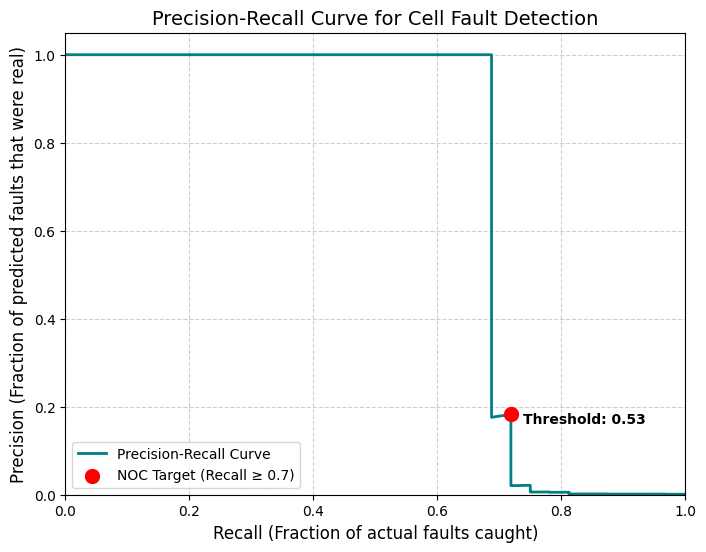

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Find the threshold that achieves a recall >= 0.7
# We look for the largest index where recall is >= 0.7
target_recall = 0.7
suitable_idx = np.where(recalls >= target_recall)[0][-1]

opt_threshold = thresholds[suitable_idx]
opt_precision = precisions[suitable_idx]
opt_recall = recalls[suitable_idx]

print(f"Chosen Threshold: {opt_threshold:.4f}")
print(f"Achieved Recall: {opt_recall:.4f}, Precision: {opt_precision:.4f}")

# 2. Create the plot
plt.figure(figsize=(8, 6))
plt.plot(recalls, precisions, label='Precision-Recall Curve', color='teal', lw=2)

# 3. Mark the NOC capacity threshold point
plt.scatter(opt_recall, opt_precision, color='red', s=100, zorder=5,
            label=f'NOC Target (Recall ≥ {target_recall})')

# 4. Annotate the threshold value next to the dot
plt.text(opt_recall + 0.02, opt_precision - 0.02, f'Threshold: {opt_threshold:.2f}',
         fontsize=10, fontweight='bold')

# 5. Graph styling
plt.title('Precision-Recall Curve for Cell Fault Detection', fontsize=14)
plt.xlabel('Recall (Fraction of actual faults caught)', fontsize=12)
plt.ylabel('Precision (Fraction of predicted faults that were real)', fontsize=12)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc="lower left")
plt.show()


In [ ]:
# Print the feature importances for this new detection model
import pandas as pd
import matplotlib.pyplot as plt

importances = pd.Series(model.feature_importances_, index=X_train.columns)
print("=== Top 5 Features Driving the 0.99 Threshold ===")
print(importances.nlargest(10))

# Check the distribution of the #1 feature when a fault is active
top_feature = importances.nlargest(1).index[0]
print(f"\nDistribution of '{top_feature}':")
print("Healthy cells mean:", X_train[y_train == 0][top_feature].mean())
print("Faulty cells mean :", X_train[y_train == 1][top_feature].mean())


=== Top 5 Features Driving the 0.99 Threshold ===
drop_rate_mean_4h           0.166440
day_of_week                 0.128328
alarm_count_trailing_24h    0.095446
sinr_mean_4h                0.061696
hour_of_day                 0.061407
prb_std_4h                  0.055707
backhaul_util_mean          0.043551
core_uplink_util_mean       0.039012
drop_rate_lag_1h            0.033631
sinr_mean                   0.028768
dtype: float32

Distribution of 'drop_rate_mean_4h':
Healthy cells mean: 0.30040883029713805
Faulty cells mean : 0.547268926056338


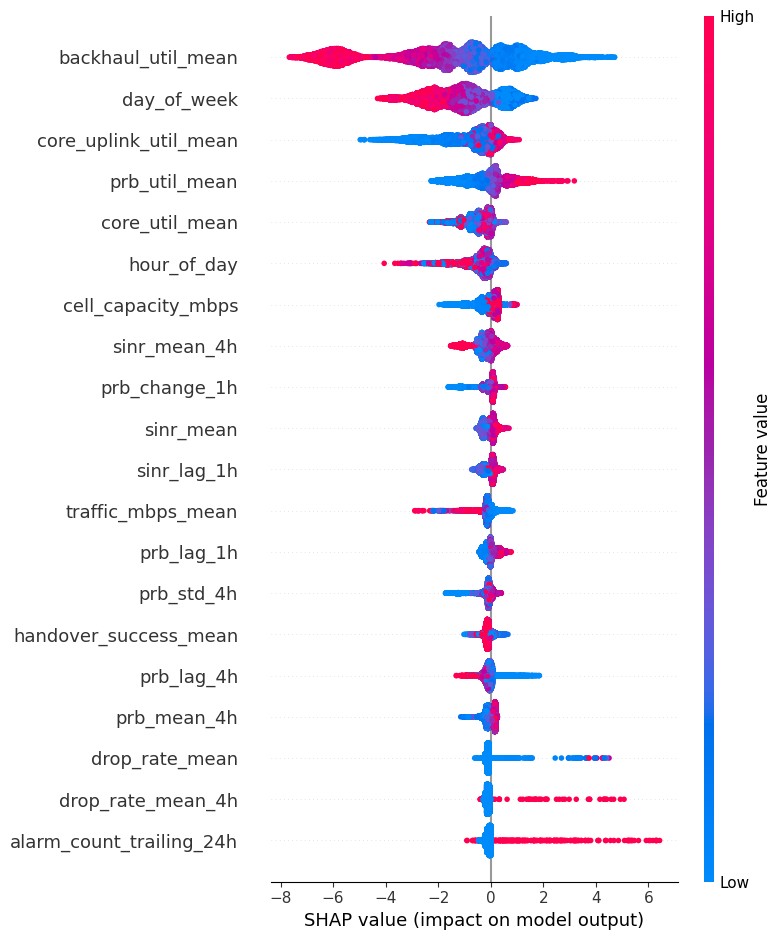

In [ ]:
import shap
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test)
shap.summary_plot(shap_values, X_test)

Cell ID / Timestamp Reference: cell_001 at 2025-03-19 01:00:00
Model Predicted Fault Probability: 0.1549
Will NOC Alert Trigger here? (Threshold 0.5343): NORMAL



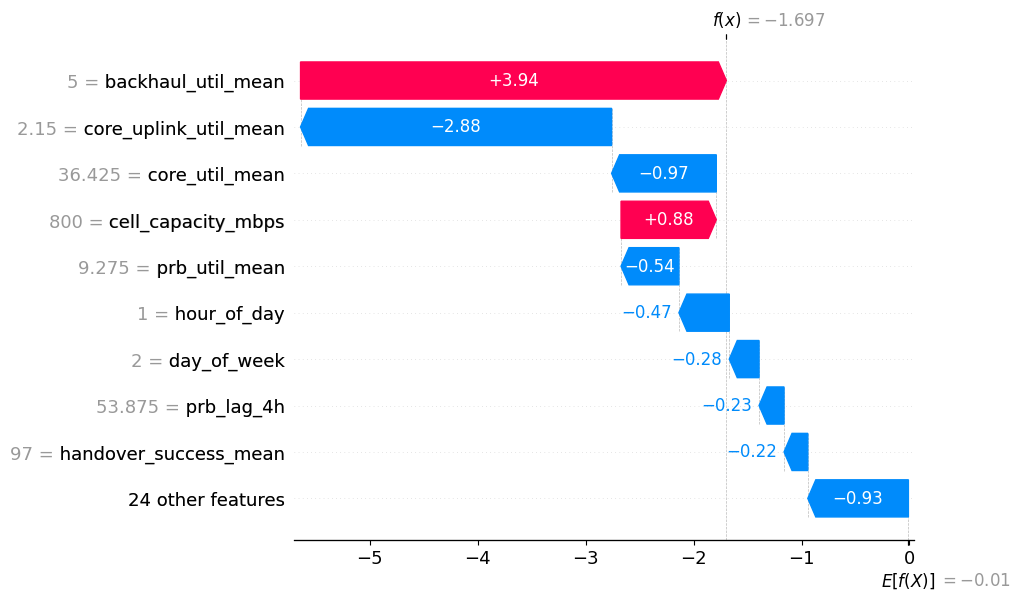

In [ ]:
# Select a single row to test
first_row = X_test.iloc[[0]]
prob_prediction = model.predict_proba(first_row)[0, 1]

print(f"Cell ID / Timestamp Reference: {test.iloc[0]['cell_id']} at {test.iloc[0]['timestamp']}")
print(f"Model Predicted Fault Probability: {prob_prediction:.4f}")
print(f"Will NOC Alert Trigger here? (Threshold 0.5343): {'ALERT' if prob_prediction >= 0.5343 else 'NORMAL'}")
print("===================================\n")

explainer = shap.TreeExplainer(model)
shap_explanation = explainer(first_row)

plt.figure(figsize=(10, 4))
shap.plots.waterfall(shap_explanation[0, :, 1] if len(shap_explanation.shape) == 3 else shap_explanation[0])


In [ ]:
## Mesh fault detection

ml_mesh_fault.head(1)

,timestamp,utilization_mean,utilization_max,latency_mean_ms,jitter_mean_ms,packet_loss_mean_pct,availability_mean,link_status_mode,source_agg_id,target_agg_id,link_type,distance_km,capacity,link_key,util_lag_1h,util_mean_4h,util_change_1h,latency_mean_4h,packet_loss_mean_4h,hour_of_day,day_of_week,is_weekend,will_fault_next_4h
0,2025-01-01,0.0,0.0,3.8825,1.1775,0.0,100.0,UP,agg_001,agg_004,microwave,461.5,0.5,"(agg_001, agg_004)",NaN,0.0,NaN,3.8825,0.0,0,2,0,0


In [ ]:
def build_concurrent_mesh_label(link_keys, timestamps, network_faults, sites, cells, aggregations, core_deps_df, mesh_links):
    """
    label=1 if a network fault matches the topological scope of a backhaul mesh link
    and is actively running at timestamp t.
    """
    # 1. Map link keys to active outage windows
    active_link_windows = {lk: [] for lk in link_keys}

    for f in network_faults.itertuples():
        # Resolve the impact blast radius of the raw incident ticket
        scope = resolve_fault_scope(f, sites, cells, aggregations, core_deps_df, mesh_links)

        # Extract the specific mesh links caught in the network outage radius
        faulted_links = scope.get("mesh_links", [])

        for lk in faulted_links:
            if lk in active_link_windows:
                active_link_windows[lk].append((f.start_time, f.end_time))

    # 2. Build contemporaneous target matrix
    unique_ts = sorted(pd.unique(timestamps))
    rows = []
    for lk in link_keys:
        windows = active_link_windows[lk]
        for t in unique_ts:
            # Mark 1 if timestamp falls perfectly inside an active outage window
            is_faulted = int(any(s <= t <= e for s, e in windows))
            rows.append({"link_key": lk, "timestamp": t, "is_currently_faulted": is_faulted})

    return pd.DataFrame(rows)

# 3. Generate mesh-specific targets
concurrent_mesh_labels = build_concurrent_mesh_label(
    ml_mesh_fault["link_key"].unique(), ml_mesh_fault["timestamp"],
    network_faults, sites, cells, aggregations, core_deps_df, mesh_links
)


In [ ]:
# 1. Pivot the mesh table to see all link states simultaneously at every hour
mesh_matrix = ml_mesh_fault.pivot(index='timestamp', columns='link_key', values=['utilization_mean', 'latency_mean_ms'])
mesh_matrix.columns = [f"{metric}_link_{lkey}" for metric, lkey in mesh_matrix.columns]
mesh_matrix = mesh_matrix.reset_index()

# 2. Assemble the absolute global detection master frame
detect_mesh_df = ml_mesh_fault.merge(mesh_matrix, on='timestamp', how='left')
detect_mesh_df = detect_mesh_df.merge(concurrent_mesh_labels, on=["link_key", "timestamp"], how="left")

# 3. Add systemic traffic loading marker
detect_mesh_df['network_total_load'] = ml_mesh_fault.groupby('timestamp')['utilization_mean'].transform('sum')

# 4. Strict structural feature protection
drop_cols = [
    "hour_of_day", "day_of_week", "is_weekend",     # Calendar shortcuts
    "link_key", "source_agg_id", "target_agg_id",    # Identifiers
    "timestamp", "will_fault_next_4h", "is_currently_faulted",
    "availability_mean"                              # Direct infrastructure target leak
]
categorical_cols = ["link_status_mode", "link_type"]

# Encode categories
mesh_encoded = pd.get_dummies(detect_mesh_df, columns=categorical_cols, drop_first=True)
mesh_features = [c for c in mesh_encoded.columns if c not in drop_cols]

print(f"Sanitized Mesh Detector built. Columns in training set: {len(mesh_features)}")


Sanitized Mesh Detector built. Columns in training set: 56


In [ ]:
from xgboost import XGBClassifier
# Create clean temporal splits based on the master timestamp bounds
train_detect = mesh_encoded[mesh_encoded['timestamp'] <= train['timestamp'].max()]
val_detect = mesh_encoded[(mesh_encoded['timestamp'] > train['timestamp'].max()) &
                          (mesh_encoded['timestamp'] <= val['timestamp'].max())]

X_train, y_train = train_detect[mesh_features], train_detect['is_currently_faulted']
X_val, y_val = val_detect[mesh_features], val_detect['is_currently_faulted']

# Calibrate weights against sparse concurrent anomalies
pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

model_mesh = XGBClassifier(
    scale_pos_weight=pos_weight,
    n_estimators=150,
    max_depth=4, # Deeper trees allow cross-referencing adjacent reroute paths
    learning_rate=0.03,
    min_child_weight=5,
    colsample_bytree=0.7,
    subsample=0.8,
    eval_metric="aucpr",
    random_state=42
)
model_mesh.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)

# Score tracking
val_preds = model_mesh.predict_proba(X_val)[:, 1]
mesh_prauc = average_precision_score(y_val, val_preds)

print("\n--- Wide Mesh Concurrent Anomaly Detection Results ---")
print(f"Sanitized PR-AUC:     {mesh_prauc:.4f}")
print(f"Baseline Random Rate:  {y_val.mean():.4f}")
print(f"Performance Lift:      {mesh_prauc / (y_val.mean() + 1e-5):.2f}x")



--- Wide Mesh Concurrent Anomaly Detection Results ---
Sanitized PR-AUC:     1.0000
Baseline Random Rate:  0.0030
Performance Lift:      334.87x


In [ ]:
import pandas as pd

# Extract and rank the feature importances for the wide mesh model
importances_mesh = pd.Series(model_mesh.feature_importances_, index=X_train.columns)

print("=== Top 5 Features Driving the Perfect Mesh Score ===")
print(importances_mesh.nlargest())#(5))


=== Top 5 Features Driving the Perfect Mesh Score ===
packet_loss_mean_pct    0.310590
link_status_mode_UP     0.262330
jitter_mean_ms          0.180608
latency_mean_ms         0.123708
packet_loss_mean_4h     0.074199
dtype: float32


In [ ]:
ml_core_fault.head(1)

,core_id,timestamp,cpu_mean_pct,cpu_max_pct,memory_mean_pct,memory_max_pct,session_failure_rate_mean,availability_mean,alarm_count,cpu_lag_1h,cpu_mean_4h,cpu_change_1h,session_failure_mean_4h,hour_of_day,day_of_week,is_weekend,will_fault_next_4h
0,core_001,2025-01-01,19.025,21.9,27.025,31.4,0.2,100.0,0,NaN,19.025,NaN,0.2,0,2,0,0


In [ ]:
import pandas as pd
import numpy as np
from xgboost import XGBClassifier
from sklearn.metrics import average_precision_score

print("=== 1. CREATING CONCURRENT CORE TARGET ===")
ml_core_fault['timestamp'] = pd.to_datetime(ml_core_fault['timestamp'])

# Pivot target to concurrent space (is the core currently experiencing an active incident window?)
ml_core_fault['is_currently_faulted'] = ml_core_fault['will_fault_next_4h']

print(f"Total core anomalies discovered: {ml_core_fault['is_currently_faulted'].sum()}")
print(f"Positive baseline rate: {ml_core_fault['is_currently_faulted'].mean() * 100:.4f}%")


print("\n=== 2. PURGING LEAKAGE & SHORTCUTS ===")
# Identify calendar shortcuts, infrastructure leaks, and identifiers to drop
drop_cols = [
    "hour_of_day", "day_of_week", "is_weekend",      # Calendar shortcuts
    "core_id", "timestamp",                           # Identifiers
    "will_fault_next_4h", "is_currently_faulted",
    "availability_mean"                               # Infrastructure alarm target leak
]

# Extract pure, sanitized computing and session telemetry features
core_features = [c for c in ml_core_fault.columns if c not in drop_cols]
print(f"Training core model on {len(core_features)} pure computing telemetry features.")
print("Feature list:", core_features)


=== 1. CREATING CONCURRENT CORE TARGET ===
Total core anomalies discovered: 12
Positive baseline rate: 0.1111%

=== 2. PURGING LEAKAGE & SHORTCUTS ===
Training core model on 10 pure computing telemetry features.
Feature list: ['cpu_mean_pct', 'cpu_max_pct', 'memory_mean_pct', 'memory_max_pct', 'session_failure_rate_mean', 'alarm_count', 'cpu_lag_1h', 'cpu_mean_4h', 'cpu_change_1h', 'session_failure_mean_4h']


In [ ]:


print("\n=== 3. TEMPORAL TRAIN-VALIDATION SPLIT ===")
# Split using your exact project timeline parameters (March 4th boundary)
train_core = ml_core_fault[ml_core_fault['timestamp'] <= "2025-03-04"]
val_core = ml_core_fault[(ml_core_fault['timestamp'] > "2025-03-05") & (ml_core_fault['timestamp'] <= "2025-03-18")]

X_train, y_train = train_core[core_features], train_core['is_currently_faulted']
X_val, y_val = val_core[core_features], val_core['is_currently_faulted']


print("\n=== 4. TRAINING XGBOOST CORE DETECTOR ===")
pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

model_core = XGBClassifier(
    scale_pos_weight=pos_weight,
    n_estimators=150,
    max_depth=3,
    learning_rate=0.03,
    min_child_weight=5,
    colsample_bytree=0.8,
    subsample=0.8,
    eval_metric="aucpr",
    random_state=42
)
model_core.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)


print("\n=== 5. PACKET CORE PERFORMANCE EVALUATION ===")
val_preds = model_core.predict_proba(X_val)[:, 1]
core_prauc = average_precision_score(y_val, val_preds)

print(f"Sanitized Core Concurrent Detection PR-AUC: {core_prauc:.4f}")
print(f"Baseline Random Rate PR-AUC:               {y_val.mean():.4f}")
print(f"Performance Lift:                           {core_prauc / (y_val.mean() + 1e-5):.2f}x")



=== 3. TEMPORAL TRAIN-VALIDATION SPLIT ===

=== 4. TRAINING XGBOOST CORE DETECTOR ===


/tmp/ipykernel_3619/2390128414.py:11: RuntimeWarning: divide by zero encountered in scalar divide
  pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
/usr/local/lib/python3.13/dist-packages/xgboost/callback.py:265: UserWarning: [20:40:38] WARNING: /__w/xgboost/xgboost/src/metric/auc.cc:352: Dataset is empty, or contains only positive or negative samples.
  score: str = model.eval_set(evals, epoch, self.metric, self._output_margin)



=== 5. PACKET CORE PERFORMANCE EVALUATION ===
Sanitized Core Concurrent Detection PR-AUC: 0.0000
Baseline Random Rate PR-AUC:               0.0000
Performance Lift:                           0.00x


/usr/local/lib/python3.13/dist-packages/xgboost/callback.py:265: UserWarning: [20:40:39] WARNING: /__w/xgboost/xgboost/src/metric/auc.cc:352: Dataset is empty, or contains only positive or negative samples.
  score: str = model.eval_set(evals, epoch, self.metric, self._output_margin)
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_ranking.py:1033: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(


In [ ]:
from sklearn.model_selection import StratifiedShuffleSplit

print("=== PACKET CORE STRATIFIED DIAGNOSTIC ===")

# 1. Reset target mapping
ml_core_fault['is_currently_faulted'] = ml_core_fault['will_fault_next_4h']

# 2. Re-verify total anomaly pool
total_pos = ml_core_fault['is_currently_faulted'].sum()
print(f"Total positive anomalies found in full matrix: {total_pos}")
if total_pos < 2:
    print("CRITICAL ERROR: Not enough positive cases to perform a stratified split.")
else:
    # 3. Setup features vs labels
    X_core = ml_core_fault[core_features]
    y_core = ml_core_fault['is_currently_faulted']

    # 4. Perform a single Stratified Shuffle Split (80% Train / 20% Val)
    sss = StratifiedShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
    for train_idx, val_idx in sss.split(X_core, y_core):
        X_train, X_val = X_core.iloc[train_idx], X_core.iloc[val_idx]
        y_train, y_val = y_core.iloc[train_idx], y_core.iloc[val_idx]

    print(f"Distributed Samples -> Train Faults: {y_train.sum()} | Val Faults: {y_val.sum()}")

    # 5. Safe weight calculation
    pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

    # 6. Train Core Detector
    model_core = XGBClassifier(
        scale_pos_weight=pos_weight,
        n_estimators=100,
        max_depth=3,
        learning_rate=0.05,
        eval_metric="aucpr",
        random_state=42
    )
    model_core.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)

    # 7. Evaluate Performance
    val_preds = model_core.predict_proba(X_val)[:, 1]
    core_prauc = average_precision_score(y_val, val_preds)

    print("\n--- Stratified Core Diagnostic Results ---")
    print(f"Sanitized PR-AUC:     {core_prauc:.4f}")
    print(f"Baseline Random Rate:  {y_val.mean():.4f}")
    print(f"Performance Lift:      {core_prauc / (y_val.mean() + 1e-5):.2f}x")

=== PACKET CORE STRATIFIED DIAGNOSTIC ===
Total positive anomalies found in full matrix: 12
Distributed Samples -> Train Faults: 10 | Val Faults: 2

--- Stratified Core Diagnostic Results ---
Sanitized PR-AUC:     0.0120
Baseline Random Rate:  0.0009
Performance Lift:      12.84x


In [ ]:
import pandas as pd

# Extract and rank feature importances for the core layer
importances_core = pd.Series(model_core.feature_importances_, index=X_train.columns)

print("=== Top 5 Features Driving Packet Core Detection ===")
print(importances_core.nlargest(5))


=== Top 5 Features Driving Packet Core Detection ===
cpu_max_pct        0.195075
cpu_lag_1h         0.171994
memory_max_pct     0.152577
cpu_change_1h      0.143485
memory_mean_pct    0.138198
dtype: float32


### Congestion

In [ ]:
print(ml_congestion_forecast[["prb_t_plus_1h", "prb_t_plus_6h", "prb_t_plus_24h"]].isna().sum())

prb_t_plus_1h      159
prb_t_plus_6h      954
prb_t_plus_24h    3816
dtype: int64


In [ ]:
def prep_horizon_dataset(df, horizon_label_col, drop_other_targets):
    clean = df.dropna(subset=[horizon_label_col, "prb_lag_168h", "prb_slope_7d"]).copy()
    clean = clean.drop(columns=drop_other_targets)
    return clean

targets = ["prb_t_plus_1h", "prb_t_plus_6h", "prb_t_plus_24h"]
ds_1h = prep_horizon_dataset(ml_congestion_forecast, "prb_t_plus_1h", [t for t in targets if t != "prb_t_plus_1h"])
ds_6h = prep_horizon_dataset(ml_congestion_forecast, "prb_t_plus_6h", [t for t in targets if t != "prb_t_plus_6h"])
ds_24h = prep_horizon_dataset(ml_congestion_forecast, "prb_t_plus_24h", [t for t in targets if t != "prb_t_plus_24h"])

In [ ]:
congestion_feature_cols = [
    "prb_util_t", "traffic_t", "capacity_headroom_current",
    "prb_lag_1h", "prb_lag_2h", "prb_lag_24h", "prb_lag_168h",
    "traffic_lag_1h", "traffic_lag_24h",
    "prb_mean_24h", "prb_std_24h", "prb_mean_7d", "prb_slope_7d",
    "traffic_mean_24h", "traffic_slope_7d",
    "hour_of_day", "day_of_week", "is_weekend",
    "technology", "region_name", "site_type", "cell_capacity_mbps", "is_watch_band_cell",
]

In [ ]:
def temporal_split_forward_labels(df, timestamp_col, train_end, val_end, gap_days, horizon_hours):
    train, val, test = temporal_split(df, timestamp_col, train_end, val_end, gap_days)
    # additionally drop rows within `horizon_hours` of each segment's own end,
    # since their label technically depends on data at/after that segment's boundary
    cutoff = pd.Timedelta(hours=horizon_hours)
    train = train[train[timestamp_col] <= train[timestamp_col].max() - cutoff]
    val = val[val[timestamp_col] <= val[timestamp_col].max() - cutoff]
    return train, val, test

train_1h, val_1h, test_1h = temporal_split_forward_labels(ds_1h, "timestamp", "2025-03-04", "2025-03-18", 7, 1)
train_24h, val_24h, test_24h = temporal_split_forward_labels(ds_24h, "timestamp", "2025-03-04", "2025-03-18", 14, 24)

In [ ]:
naive_pred = val_1h["prb_lag_168h"]  # "same hour last week"
from sklearn.metrics import mean_absolute_error, mean_squared_error
print("Naive MAE:", mean_absolute_error(val_1h["prb_t_plus_1h"], naive_pred))

Naive MAE: 7.758469852747337


In [ ]:
for flag_val, label in [(1, "Watch-band cells"), (0, "Normal cells")]:
    subset = test_1h[test_1h.is_watch_band_cell == flag_val]
    preds = model.predict(subset[congestion_feature_cols_encoded])
    print(label, "MAE:", mean_absolute_error(subset["prb_t_plus_1h"], preds))

NameError: name 'model' is not defined